# Customer Retention Intelligence
## Company A | GCI World 2026 | Omar Cano
**Same commercial resources. Better decisions. Higher expected retention value.**

Companion to the 15-slide business proposal. This notebook is self-contained for the aggregate evidence and economic simulation, using the Python standard library; charts are optional (`matplotlib`). It embeds the original development-only EDA and frozen Q0062 recipe as readable source code. No data rows, customer identifiers, individual predictions or fitted model objects are distributed.

**Execution contract:** Run All in a normal Python kernel: it recreates a temporary workspace, validates aggregate metrics, charts observed/exploratory evidence, and regenerates R02. The last section offers an explicitly opt-in, authorized local development reconstruction using the original official assignment ZIP and private Plan Maestro v2.0 ZIP. It is disabled by default. The D-030 reserve was consumed once and is not rerun. Default execution does not reproduce model fitting or the holdout from raw data.

Evidence labels: **observed** (retrospective development data); **exploratory** (internal validation); **confirmatory offline** (frozen D-030 aggregate); **simulated** (R02, conditional); **proposed** (operating model and pilot). UM denotes unconfirmed monetary units.

In [1]:
from pathlib import Path
import base64, hashlib, io, zipfile, tempfile, csv, json, math, subprocess, sys
from IPython.display import display, Markdown
workspace = tempfile.TemporaryDirectory(prefix="gci_company_a_")
root = Path(workspace.name)
def write(rel, content):
    p = root / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(content, encoding="utf-8")
def table(rel):
    with (root / rel).open(newline="", encoding="utf-8") as f: return list(csv.DictReader(f))
def obj(rel): return json.loads((root / rel).read_text(encoding="utf-8"))
def show(rows, fields, limit=20):
    def fmt(x):
        if isinstance(x, float): return f"{x:,.4f}"
        return str(x).replace("|", "/")
    display(Markdown("| " + " | ".join(fields) + " |\n|" + "---|"*len(fields) + "\n" + "\n".join("| " + " | ".join(fmt(r.get(k,'')) for k in fields) + " |" for r in rows[:limit])))
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
print("Python", sys.version.split()[0], "| temporary workspace created")

Python 3.13.5 | temporary workspace created


### Embedded input bundle
The next cell contains a compressed, versioned copy of the aggregate CSV/JSON evidence and text configuration/reference files. SHA-256 verification guards against accidental changes. No network access is required. The source scripts themselves are included as separate readable cells below.

In [2]:
bundle = (
    '...'
)
raw = base64.b64decode(bundle)
assert hashlib.sha256(raw).hexdigest() == 'b732163c450142c409d24cd9ae2f8375e7443f62eea349228051167ebbf7cab2'
with zipfile.ZipFile(io.BytesIO(raw)) as z:
    for n in z.namelist():
        assert not Path(n).is_absolute() and ".." not in Path(n).parts
    z.extractall(root)
print("Embedded aggregate/configuration files:", len(z.namelist()))

Embedded aggregate/configuration files: 67


## 1. Market and opportunity screening (slides 2–5)
US reference market (not Company A's actual market or currency): CTIA connections rose from 469M (2020) to 603M (2025); AT&T/T-Mobile reported 0.90%/0.93% FY2025 postpaid phone churn. Competition and recurring revenue justify assessing retention, plan fit, service, care, devices, household sales and credit. Sources: [CTIA](https://www.ctia.org/news/2026-annual-survey-highlights), [AT&T FY2025](https://www.sec.gov/Archives/edgar/data/732717/000073271726000120/t-20251231.htm), [T-Mobile FY2025](https://www.sec.gov/Archives/edgar/data/1283699/000128369926000010/tmus-20251231.htm).

D-028 evaluated seven candidates (six scored). Historical F4 weights are fixed; the economic criterion mixes different estimands, so the other 70% can be shown as a diagnostic only. P01 was the most defensible analytical PoC, not a proven investment winner. P07 is not eligible (ND).

| project | impacto | relevancia | escala | datos | analitica | implementacion | riesgos | valor | factibilidad | score | score_without_economics |
|---|---|---|---|---|---|---|---|---|---|---|---|
| P01 | 1 | 5 | 4 | 4 | 4 | 3 | 3 | 2.8333333333333335 | 3.6250000000000004 | 3.15 | 4.0714 |
| P04 | 2 | 4 | 4 | 3 | 3 | 2 | 2 | 3.0 | 2.625 | 2.85 | 3.2143 |
| P02 | 1 | 4 | 4 | 3 | 3 | 3 | 2 | 2.5 | 2.875 | 2.65 | 3.3571 |
| P05 | 1 | 3 | 3 | 3 | 3 | 3 | 2 | 2.0000000000000004 | 2.875 | 2.35 | 2.9286 |
| P06 | 1 | 4 | 3 | 2 | 3 | 2 | 2 | 2.3333333333333335 | 2.25 | 2.3 | 2.8571 |
| P03 | 1 | 4 | 3 | 2 | 2 | 2 | 2 | 2.3333333333333335 | 2.0 | 2.2 | 2.7143 |

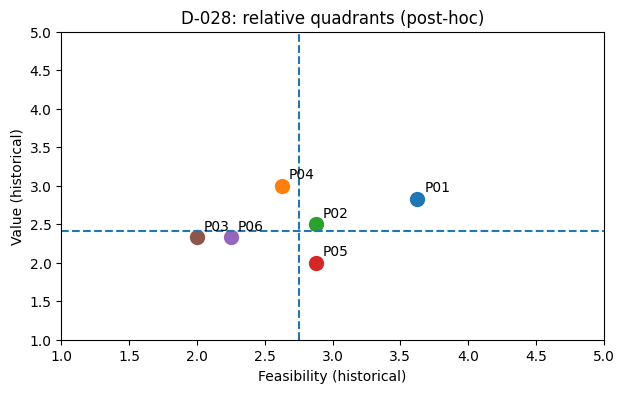

In [3]:
weights = dict(impacto=.30,relevancia=.20,escala=.10,datos=.15,analitica=.10,implementacion=.10,riesgos=.05)
rank = table("evidence/f4/ranking_refinado.csv")
for r in rank:
    score = sum(float(r[k])*w for k,w in weights.items())
    assert math.isclose(score,float(r['score']),abs_tol=1e-10)
    r['score_without_economics'] = (score-.30*float(r['impacto']))/.70
show(rank,['project',*weights,'valor','factibilidad','score','score_without_economics'])
if plt:
    fig,ax=plt.subplots(figsize=(7,4));
    for r in rank:
        x,y=float(r['factibilidad']),float(r['valor']); ax.scatter(x,y,s=100); ax.annotate(r['project'],(x,y),xytext=(5,5),textcoords='offset points')
    ax.axvline(2.75,ls='--'); ax.axhline(2.4166666667,ls='--'); ax.set(xlim=(1,5),ylim=(1,5),xlabel='Feasibility (historical)',ylabel='Value (historical)',title='D-028: relative quadrants (post-hoc)');plt.show()

## 2. Data audit and EDA (slide 6)
100,000 original matched records; 70,000 development records; 30,000 retrospective reserve consumed at D-030. One customer record, not a verified household. 49.56% sample label share is not commercial prevalence. Missingness, revenue and service patterns are descriptive, not causal.

Development audit: {
  "n": 70000,
  "columns": 100,
  "target_1": 34693,
  "churn_share": 0.49561428571428573,
  "missing_cells": 240660,
  "complete_rows": 18604,
  "revenue_positive_sum": 4102640.044166657,
  "churn_revenue_positive_sum": 2010716.167500006
}
Cell completeness: 0.96562
Full rows: 0.26577142857142855


| rule | eligible_n | n | churn_rate | control_rate | gap_pp | standardized_gap_pp | common_support |
|---|---|---|---|---|---|---|---|
| H1_old_equipment | 69895 | 7623 | 0.5779876688967598 | 0.4857720966084275 | 9.221557228833227 | 8.48607024149158 | 0.5477215823735604 |
| H2_usage_decline | 69370 | 37619 | 0.5131715356601717 | 0.46956001385783125 | 4.361152180234046 | 4.209116712831834 | 1.0 |
| H3_failure_ge10pct | 55130 | 10464 | 0.5162461773700305 | 0.47423095867102494 | 4.20152186990056 | 3.986582567136393 | 0.9976600761835661 |
| H4_care_ge3 | 70000 | 12181 | 0.45012724735243415 | 0.505197253497985 | -5.507000614555091 | -1.9769199681426517 | 0.9330857142857143 |
| H5_overage_ge20 | 69738 | 13986 | 0.5195195195195195 | 0.48868202037595065 | 3.0837499143568814 | 8.709904527437752 | 0.821202214000975 |
| H6_revenue_ge100 | 69738 | 7832 | 0.48965781409601633 | 0.4955254741059025 | -0.5867660009886144 | 8.755093099047194 | 0.7480713527775388 |
| H7_multi_active | 70000 | 20535 | 0.5165327489651814 | 0.48693015263317496 | 2.960259633200646 | 2.7384980353438517 | 0.9987428571428572 |
| H8_revenue100_old | 69633 | 294 | 0.6020408163265306 | 0.4946278429166847 | 10.741297340984591 | 15.942772759190868 | 0.0916232246205104 |
| H9_decline_old | 69265 | 4150 | 0.588433734939759 | 0.48736850188128694 | 10.10652330584721 | 13.405969945975292 | 0.4267812026275897 |
| H10_decline_overage | 69370 | 7306 | 0.522036682179031 | 0.4898169631348286 | 3.22197190442024 | 8.790786560580106 | 0.818970736629667 |

| top_fraction | n | revenue_share | churn_rate | exposure_share |
|---|---|---|---|---|
| 0.01 | 698 | 0.05479556092658952 | 0.5229226361031518 | 0.058379548738571346 |
| 0.05 | 3487 | 0.16909859038686811 | 0.4961284772010324 | 0.17219884168460037 |
| 0.1 | 6974 | 0.26945493668283743 | 0.4866647548035561 | 0.2699370165249334 |
| 0.2 | 13947 | 0.42208080378931423 | 0.48383164838316484 | 0.41984171667038 |
| 0.5 | 34867 | 0.7291675629095354 | 0.48796856626609686 | 0.727070439443351 |

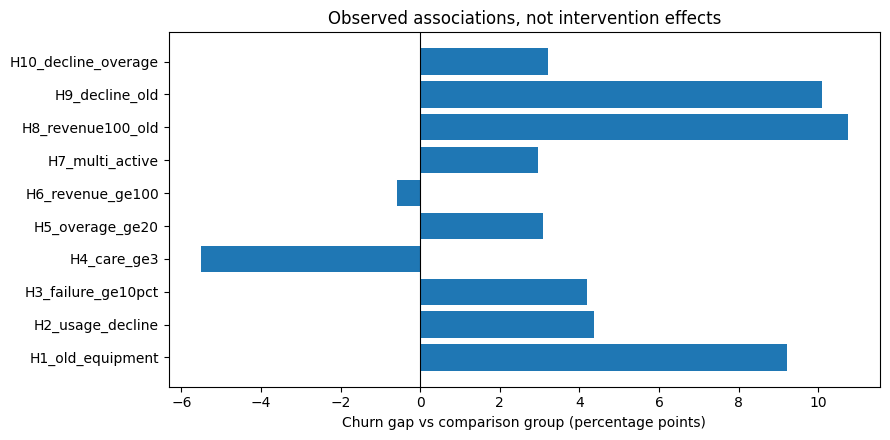

In [4]:
a=obj('evidence/f5/audit.json'); print('Development audit:', json.dumps({k:a[k] for k in ['n','columns','target_1','churn_share','missing_cells','complete_rows','revenue_positive_sum','churn_revenue_positive_sum']},indent=2))
print('Cell completeness:',1-a['missing_cells']/(a['n']*a['columns'])); print('Full rows:',a['complete_rows']/a['n'])
h=table('evidence/f5/hypotheses.csv'); show(h,['rule','eligible_n','n','churn_rate','control_rate','gap_pp','standardized_gap_pp','common_support'])
show(table('evidence/f5/revenue_concentration.csv'),['top_fraction','n','revenue_share','churn_rate','exposure_share'])
if plt:
    fig,ax=plt.subplots(figsize=(9,4.5)); ax.barh([r['rule'] for r in h],[float(r['gap_pp']) for r in h]); ax.axvline(0,color='black',linewidth=.8); ax.set(xlabel='Churn gap vs comparison group (percentage points)',title='Observed associations, not intervention effects');fig.tight_layout();plt.show()

## 3. Problem, features and selection (slides 7–8)
Target: binary churn in days 31–60 following observation, not cumulative 60-day churn. No individual dates or verified as-of timing; no temporal validation claim. Train 52,500, internal validation 17,500; stratified five-fold CV within train. Fit transforms and Platt calibration only on training folds/OOF scores. Exclude identifiers, protected attributes and other audit-only fields. Construct ratios and recent changes with valid denominators; evaluate removal of lifetime features and ambiguous change fields.

Q0062 = 80% calibrated P072 (50/50 raw average of two LightGBM branches, one OOF Platt calibration) + 20% independently OOF-Platt-calibrated expert no-lifetime branch. Model selection uses weighted exposure at 5% capacity under a hypothetical 1% prior, with guardrails; AUC/AP and calibration scores are complementary. The exact recipe is shown below, not optimized here.

In [5]:
recipe=obj('model/diagnostico/fase6/corte05/results/proposal05.json'); print(json.dumps(recipe,indent=2))
print(json.dumps(obj('evidence/f6/resolved05.json'),indent=2))
features=obj('evidence/f6/candidate_feature_lists.json'); print('Exact feature list by component:')
for name,cols in features.items(): print(name,len(cols),', '.join(cols))
cv=table('evidence/f6/global_cv_shortlist.csv'); show(cv,list(cv[0]),10)
print('Internal validation only:'); v=table('evidence/f6/validation05.csv'); show(v,['name','auc','ap','brier','logloss','exposure','precision','recall','relative'],10)

{
  "name": "Q0062",
  "weights": {
    "P072": 0.8,
    "expert_nolife": 0.19999999999999996
  },
  "cv_auc": 0.695629995576259,
  "cv_exposure": 136.81079331905565,
  "cv_sd": 7.516769931856242,
  "source": "C05 search / C04 OOF",
  "train_n": 52500,
  "baseline": "B1_revenue",
  "alpha": 1,
  "prior": 0.01,
  "k": 0.05,
  "calibration": "component OOF train; arithmetic mixture if applicable",
  "selection": "maximum mean CV exposure among shortlisted with guardrails; no selection from internal validation",
  "status": "proposed; gate required; reserve unopened"
}
{
  "P072": {
    "names": [
      "LGB_no_life",
      "sector_select25"
    ],
    "weights": {
      "LGB_no_life": 0.5,
      "sector_select25": 0.5
    },
    "configs": {
      "LGB_no_life": {
        "name": "LGB_no_life",
        "family": "lgb",
        "features": "no_lifetime",
        "params": {
          "num_leaves": 31,
          "max_depth": 8,
          "n_estimators": 160,
          "learning_rate": 0.06

| name | source | auc | exposure | sd | brier | logloss | low_rel | high_rel | weights | components |
|---|---|---|---|---|---|---|---|---|---|---|
| Q0062 | C05 search / C04 OOF | 0.695629995576259 | 136.81079331905565 | 7.516769931856242 | 0.2202964170625084 | 0.6298414572654203 | 0.4257898478418322 | 0.4117382767013986 | {"P072": 0.8, "expert_nolife": 0.19999999999999996} | 2 |
| Q0548 | C05 search / C04 OOF | 0.6977854154717148 | 136.77404842083848 | 8.976068154506907 | 0.2196938102856337 | 0.6285329920350028 | 0.4239907865525836 | 0.4036000907177497 | {"P038": 0.239043417912976, "P072": 0.5652644601044101, "expert_select35": 0.19569212198261393} | 3 |
| C03final_blend_diverse | C03 archive calibrated | 0.6995858475701935 | 136.76895260185387 | 11.182862057618886 | 0.2191062873016917 | 0.6272170831908628 | 0.4280975536146282 | 0.4138998729106928 | {"C03final_blend_diverse": 1} | 3 |
| Q0473 | C05 search / C04 OOF | 0.6972973090650696 | 136.6466593956224 | 9.031835029568024 | 0.2198363643090405 | 0.6288864171349302 | 0.4217139631412869 | 0.4065688113664139 | {"P025": 0.16784547990343368, "STACK": 0.21316313399814685, "expert_nolife": 0.33401637749580876, "expert_select35": 0.13030888370159097, "expert_shallow": 0.15466612490101986} | 5 |
| Q0665 | C05 search / C04 OOF | 0.69682430404453 | 136.4402012096994 | 7.593506266675258 | 0.2199559613659796 | 0.6290903116872263 | 0.4206557128388484 | 0.4081026286308737 | {"P038": 0.1527692060312064, "P072": 0.5799561073925596, "expert_nolife": 0.20010444805786923, "expert_shallow": 0.06717023851836475} | 4 |
| Q0318 | C05 search / C04 OOF | 0.6994610379884402 | 136.38841664376974 | 10.078158516015128 | 0.2191894593127678 | 0.6274021817562326 | 0.4220229249635563 | 0.3972699563058035 | {"P038": 0.6889116167943553, "STACK": 0.101887479165248, "expert_select35": 0.2092009040403967} | 3 |
| C03final_blend_value | C03 archive calibrated | 0.7009187390132154 | 135.9051743532383 | 8.677484390264585 | 0.2186931659113815 | 0.626238801593955 | 0.4253455329033504 | 0.4018766059311055 | {"C03final_blend_value": 1} | 3 |
| C03final_blend_conservative | C03 archive calibrated | 0.695709471972524 | 135.21327618975596 | 8.765029308881678 | 0.2201903430549783 | 0.6295001850793159 | 0.4127944775191075 | 0.3983085496323442 | {"C03final_blend_conservative": 1} | 3 |
| Q0006 | C05 search / C04 OOF | 0.6955682402683504 | 135.14996472536075 | 6.7253543736806805 | 0.2203371221988388 | 0.6299560262896479 | 0.413573421781932 | 0.3980692080773631 | {"P072": 1.0} | 1 |
| Q0007 | C05 search / C04 OOF | 0.6995263491248889 | 135.1036963928285 | 9.207918651629525 | 0.2191660529379209 | 0.6273066649564498 | 0.4074517888220923 | 0.3884464284148547 | {"P038": 1.0} | 1 |

Internal validation only:


| name | auc | ap | brier | logloss | exposure | precision | recall | relative |
|---|---|---|---|---|---|---|---|---|
| C05 proposed | 0.6878116445419166 | 0.6804377217117766 | 0.22230754266191854 | 0.6340146872482602 | 152.4040815931554 | 0.027517401392110914 | 0.13758700696055684 | 0.3242256055760513 |
| C04 P072 | 0.6876359705295578 | 0.680468305254045 | 0.22236700425823494 | 0.6341294352174448 | 148.07440641914152 | 0.027122969837586594 | 0.13561484918793504 | 0.28660544035920554 |
| C04 P038 | 0.6922821295117827 | 0.6846157360750837 | 0.22114132457508098 | 0.631424655212491 | 152.47959010046404 | 0.02800464037122928 | 0.14002320185614853 | 0.324881692327611 |
| C04 stacking | 0.6913827684366898 | 0.6838041897322314 | 0.22134306719464186 | 0.631864168221969 | 155.4995330866676 | 0.028662275721115456 | 0.14331137860557966 | 0.35112171023202765 |
| C02 ensemble | 0.690921906625102 | 0.6831320278194083 | 0.2215761574032105 | 0.6324986897188662 | 152.73725831390948 | 0.02774941995359586 | 0.13874709976798144 | 0.32712054867857376 |
| C03 diverse | 0.6921880552878995 | 0.6851141438820276 | 0.22118069569012477 | 0.6315932023213444 | 152.885101508051 | 0.028747099767981003 | 0.1437354988399072 | 0.32840514513587205 |
| C03 value | 0.6936075546016816 | 0.6866465625051881 | 0.22077086098805687 | 0.6306251789677869 | 150.24963167045243 | 0.028445475638050628 | 0.14222737819025524 | 0.3055057804653911 |
| C03 conservative | 0.6893118423498878 | 0.6807377136008963 | 0.2220333721424272 | 0.6334800107065994 | 153.67863592421114 | 0.028027842227377715 | 0.14013921113689096 | 0.3353000955978307 |

## 4. Confirmatory offline result (slide 9)
The following cells verify published aggregate identities, not re-estimate D-030. The bootstrap interval is conditional on the fitted models, and the holdout is retrospective, not an external or temporal test. Weighting assumes label shift; deployment probabilities are not calibrated to a real population. B1 is a strong simple reference, not actual BAU. B4 is the logistic benchmark.

For assumed prior p and sample churn fraction q, evaluation weights are p/q for churn and (1-p)/(1-q) otherwise. At equal weighted capacity, rank by adjusted risk times nonnegative historical revenue. Captured exposure = 1,000 × sum(weight × churn × revenue within top-k)/total eligible weight; fractional boundary mass is used offline. It is not incremental profit.

B1 105.89184, Q0062 137.72057 UM/1K; improvement 30.06%; delta 31.82873, paired 95% CI [24.584351023742638, 39.338488110228816]; gate 3/3


| name | n | auc | ap | brier | logloss |
|---|---|---|---|---|---|
| Q0062 | 30000 | 0.6921928609852771 | 0.683850699496655 | 0.22099186319953643 | 0.6310090976854151 |
| B4_F3_original | 30000 | 0.595391708964967 | 0.575915497556482 | 0.24334318093583773 | 0.6798609126050432 |
| B0_constant | 30000 | 0.5 | 0.4956333333333333 | 0.24998093242630393 | 0.693109044927796 |

| name | policy | exposure | precision | recall | lift | exposure_recall |
|---|---|---|---|---|---|---|
| B1_revenue | rule | 105.89184115724416 | 0.010915231340763073 | 0.05457615670381627 | 1.0915231340763072 | 0.1822763898378632 |
| B2_decline | rule | 61.907316221985816 | 0.012225599459641709 | 0.061127997298210064 | 1.2225599459641707 | 0.10656384837749697 |
| B3_device | rule | 32.28081841721039 | 0.015589327929753101 | 0.0779466396487673 | 1.55893279297531 | 0.05556642492751846 |
| Q0062 | risk | 92.59600247661803 | 0.03670381627828302 | 0.18351908139142187 | 3.670381627828302 | 0.15938966458985904 |
| Q0062 | value | 137.72056793879094 | 0.025558932792974557 | 0.12779466396487674 | 2.5558932792974556 | 0.2370646090951045 |
| B4_F3_original | risk | 63.65416188229786 | 0.018047956771360535 | 0.09023978385680513 | 1.8047956771360534 | 0.10957077239624928 |
| B4_F3_original | value | 115.35982044362038 | 0.014724755150286737 | 0.07362377575143533 | 1.4724755150286737 | 0.19857404851033467 |
| B0_random_expected | rule | 29.047053557357614 | 0.01 | 0.05 | 1.0 | 0.05 |

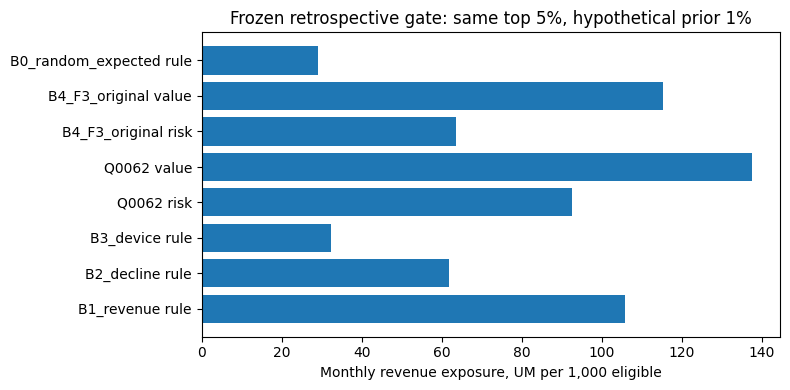

In [6]:
s=obj('evidence/f6/summary.json'); delta=s['candidate']-s['reference']; relative=delta/s['reference']; assert math.isclose(delta,s['delta'],abs_tol=1e-10) and math.isclose(relative,s['relative'],abs_tol=1e-10)
gate=[relative>=.10,s['ci95'][0]>0,min(s['guardrails'].values())>=-.05]; assert all(gate)
print(f"B1 {s['reference']:.5f}, Q0062 {s['candidate']:.5f} UM/1K; improvement {relative:.2%}; delta {delta:.5f}, paired 95% CI {s['ci95']}; gate {sum(gate)}/3")
pr=[r for r in table('evidence/f6/predictive.csv') if r['scope']=='all' and r['prior']=='sample'];show(pr,['name','n','auc','ap','brier','logloss'])
grid=table('evidence/f6/policy_grid.csv'); top=[r for r in grid if math.isclose(float(r['prior']),.01) and math.isclose(float(r['k']),.05)]; show(top,['name','policy','exposure','precision','recall','lift','exposure_recall'])
if plt:
    fig,ax=plt.subplots(figsize=(8,4)); ax.barh([r['name']+' '+r['policy'] for r in top],[float(r['exposure']) for r in top]); ax.set(xlabel='Monthly revenue exposure, UM per 1,000 eligible',title='Frozen retrospective gate: same top 5%, hypothetical prior 1%');fig.tight_layout();plt.show()

## 5. Commercial productivity and operating design (slides 10–11)
F7 uses the internal validation set already seen during development. Top 20% is exploratory, not confirmatory. Same business lane (25%) in both annual policies; the remaining 75% uses B1 vs Q0062, with fallback, capacity constraints, permission checks, learning/adoption, decay and unique opportunities. No claim of optimal 75/25 or causal targeting. Profiles are routing rules, not natural clusters or reasons for churn.

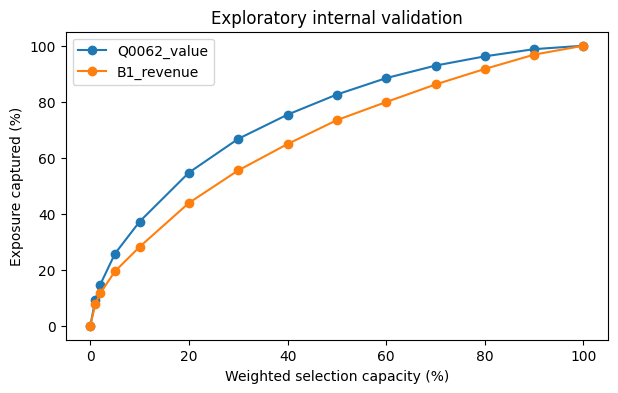

| k | exposure_A | exposure_B1 | relative | saves_A | saves_B1 | margin_delta | common_contact_cost_each | cost_per_save_A | cost_per_save_B1 |
|---|---|---|---|---|---|---|---|---|---|
| 0.2 | 323.91140467900226 | 259.74932907966354 | 0.2470153660326131 | 0.3826774941995652 | 0.20920649651973477 | 19.07069474574943 | 78.99999999999999 | 206.44015181828726 | 377.6173365273472 |

One wave, 1,000 eligible; conditional on equal response, reach, margin and persistence. Not an annual projection.


| hierarchy | k | profile | raw_n | weighted_share | churn_rate | exposure_um_per_1k | exposure_share | mean_revenue |
|---|---|---|---|---|---|---|---|---|
| Service>Billing>Lifecycle>Disengagement | 1.0 | Service | 2684 | 0.1483122367527382 | 0.010786486782649504 | 102.43910962873552 | 0.17299270323950966 | 62.19350280064655 |
| Service>Billing>Lifecycle>Disengagement | 1.0 | Billing | 2906 | 0.1568032582193299 | 0.011297352727579141 | 199.44289926527847 | 0.3368065811082316 | 109.16845385434372 |
| Service>Billing>Lifecycle>Disengagement | 1.0 | Lifecycle | 1514 | 0.0761914980452619 | 0.012865981735803278 | 36.26787703016241 | 0.06124690180288285 | 36.781039116154346 |
| Service>Billing>Lifecycle>Disengagement | 1.0 | Disengagement | 5542 | 0.3159636094984464 | 0.010133623152281982 | 145.47465777261021 | 0.24566842090032162 | 46.77533259622129 |
| Service>Billing>Lifecycle>Disengagement | 1.0 | Unclassified | 4780 | 0.30272939748422356 | 0.008081923166996342 | 108.53401392114849 | 0.18328539294905438 | 47.372957463370135 |
| Service>Billing>Lifecycle>Disengagement | 0.05 | Service | 350 | 0.2172955688828453 | 0.02733454347251874 | 30.782953402900237 | 0.20198247370484276 | 136.46832975756584 |
| Service>Billing>Lifecycle>Disengagement | 0.05 | Billing | 765 | 0.6018905481550558 | 0.019351245541643247 | 91.93292923433874 | 0.6032182883379383 | 163.1093259274726 |
| Service>Billing>Lifecycle>Disengagement | 0.05 | Lifecycle | 62 | 0.025916431161415048 | 0.045658086802274754 | 2.9166038283062647 | 0.019137307858277535 | 54.55218299620405 |
| Service>Billing>Lifecycle>Disengagement | 0.05 | Disengagement | 378 | 0.13561041222157422 | 0.054920530818067255 | 22.872349187935036 | 0.15007701203825397 | 77.66280443557565 |
| Service>Billing>Lifecycle>Disengagement | 0.05 | Unclassified | 64 | 0.019287039579109693 | 0.06736668626546682 | 3.899245939675174 | 0.025584918060687235 | 78.51852641931012 |

| k | scenario | exposure_um_per_1k | vs_model_only |
|---|---|---|---|
| 0.05 | model_only | 152.40408159315547 | 0.0 |
| 0.05 | hybrid_zero_exposure | 128.50177010823668 | -0.15683511383065374 |
| 0.05 | hybrid_random_remaining | 134.52328682914185 | -0.1173249074243734 |
| 0.05 | hybrid_model_backfill | 152.40408159315547 | 0.0 |
| 0.1 | model_only | 220.2582115235383 | 0.0 |
| 0.1 | hybrid_zero_exposure | 189.2823675560673 | -0.14063422994861063 |
| 0.1 | hybrid_random_remaining | 200.1709132334151 | -0.09119886224072316 |
| 0.1 | hybrid_model_backfill | 220.2582115235383 | 0.0 |
| 0.2 | model_only | 323.9114046790023 | 0.0 |
| 0.2 | hybrid_zero_exposure | 273.04697215772626 | -0.1570319284425411 |

| scope | group | n | mean_abs_pp | mean_signed_pp | positive_share |
|---|---|---|---|---|---|
| eligible | Billing | 128 | 0.2320811717608332 | -0.028911647873415627 | 0.46875 |
| eligible | Service | 128 | 0.11010880852951352 | 0.00302667731551135 | 0.4765625 |
| eligible | Lifecycle | 128 | 0.4450475096874891 | -0.06103815123224487 | 0.421875 |
| eligible | Engagement | 128 | 0.31635212105726573 | -0.039258531642421046 | 0.46875 |
| eligible | Other | 128 | 0.01182600891754476 | -0.002782871946355463 | 0.453125 |
| top20 | Billing | 128 | 0.32852243694197647 | 0.18378442617948515 | 0.65625 |
| top20 | Service | 128 | 0.17567456006730367 | 0.10165331786796512 | 0.671875 |
| top20 | Lifecycle | 128 | 0.5088338692204831 | 0.20673327673620062 | 0.6875 |
| top20 | Engagement | 128 | 0.6020788384177982 | 0.2918951765332182 | 0.546875 |
| top20 | Other | 128 | 0.014464620079874486 | 0.0033518599405727967 | 0.5859375 |

In [7]:
g=table('economics/inputs/capacity_grid.csv')
if plt:
    fig,ax=plt.subplots(figsize=(7,4));
    for pol in ['Q0062_value','B1_revenue']:
        v=sorted([(float(r['k']),float(r['exposure_recall'])) for r in g if r['policy']==pol and float(r['prior'])==.01]); ax.plot([0]+[100*x for x,y in v],[0]+[100*y for x,y in v],marker='o',label=pol)
    ax.set(xlabel='Weighted selection capacity (%)',ylabel='Exposure captured (%)',title='Exploratory internal validation');ax.legend();plt.show()
w=next(r for r in table('economics/results/one_wave.csv') if float(r['k'])==.2);show([w],['k','exposure_A','exposure_B1','relative','saves_A','saves_B1','margin_delta','common_contact_cost_each','cost_per_save_A','cost_per_save_B1'])
print('One wave, 1,000 eligible; conditional on equal response, reach, margin and persistence. Not an annual projection.')
for p in ['profiles_exclusive.csv','hybrid_stress.csv','group_shapley.csv']:
    t=table('evidence/f7/'+p); show(t,list(t[0]),10)

## 6. Reproducible marginal economic simulation (slides 12–13)
The original D-032 simulator is included below, unchanged. The two arms hold commercial resources and business lane constant by assumption; common costs cancel only when genuinely equivalent. Margin is differential, costs are own Analytics build/run and any differential costs, not the whole CRM. Scenarios vary assumed prior, response, persistence, margin, etc. All seven archived outputs are checked byte-for-byte.

In [8]:
write('economics/simulate_marginal.py', r'''
"""Matched-capacity marginal Analytics value; aggregates only; stdlib Python 3."""
import csv,json,itertools,math
from pathlib import Path
from dataclasses import dataclass,replace,asdict
P=Path(__file__).resolve().parent; O=P/'results'; O.mkdir(exist_ok=True)
G=list(csv.DictReader((P/'inputs/capacity_grid.csv').open())); TECH=17426/17500
@dataclass
class Params:
    N:int=100000; months:int=12; prior:float=.01; elig:float=.8; fresh:float=.5; k:float=.2; share:float=.75
    human:float=.3; agents:float=20; hours:float=30; minutes:float=10; digital:float=12000
    reach_d:float=.65; reach_h:float=.75; response:float=.15; margin:float=.55; persist:int=6; survival:float=.95
    decay:float=.025; saturation:float=.2; replenishment:bool=False; reset_quality:bool=False
    adoption:tuple=(0,0,.30,.50,.65,.80,.85,.90,.90,.90,.90,.90)
    build_hours:float=160; monthly_hours:float=8; hourly_rate:float=15; integration_extra:float=0; platform_extra:float=0
    contact_h:float=1.2; contact_d:float=.05; extra_per_migrated:float=0; discount_rate:float=.1
B=Params()
def curve(p,policy,k):
    a=[(0.,0.,0.)]+sorted((float(r['k']),float(r['exposure'])/1000,float(r['precision'])*float(r['k'])) for r in G if float(r['prior'])==p.prior and r['policy']==policy)
    for (x,e,c),(y,f,d) in zip(a,a[1:]):
        if x<=k<=y+1e-12:
            w=(k-x)/(y-x);return e+w*(f-e),c+w*(d-c)
    raise ValueError(k)
def sim(p):
    untreated=unassigned=p.N; hist=[]; pending=(0.,0.,0.,0.); rows=[]; cum=0; prior_stock=0; unique=0
    for m in range(1,p.months+1):
        hist.append((m,*pending)); stock=sum((a-b)*p.survival**(m-t) for t,a,b,ea,eb in hist if m-t<p.persist); rev=sum((ea-eb)*p.survival**(m-t) for t,a,b,ea,eb in hist if m-t<p.persist)
        pool=unassigned*p.elig*TECH*p.fresh; cap=min(pool*p.k,p.agents*p.hours*60/p.minutes/p.human if p.human else math.inf,p.digital/(1-p.human) if p.human<1 else math.inf)
        adoption=p.adoption[min(m-1,11)]; business=cap*(1-p.share); switched=cap*p.share*adoption; fallback=cap-business-switched
        # Business first, assumed random representative selection, identical in both arms. Fallback and adopted strata representative of remaining pool.
        residual=pool-business; adopted_pool=residual*adoption; k=switched/adopted_pool if adopted_pool else 0
        eb,cb=curve(p,'B1_revenue',k); ea,ca=curve(p,'Q0062_value',k); et,ct=curve(p,'Q0062_value',1.)
        age=max(0,m-3); age=age%12 if p.reset_quality else age; q=(1-p.decay)**age
        ea=q*ea+(1-q)*et*k; ca=q*ca+(1-q)*ct*k
        reach=p.human*p.reach_h+(1-p.human)*p.reach_d; sat=1-p.saturation*max(0,1-unassigned/p.N); response=p.response*sat
        sa=adopted_pool*ca*reach*response; sb=adopted_pool*cb*reach*response; ra=adopted_pool*ea*reach*response; rb=adopted_pool*eb*reach*response
        pending=(sa,sb,ra,rb); margin=rev*p.margin
        build=p.build_hours*p.hourly_rate/2+p.integration_extra/2 if m<=2 else 0; run=p.monthly_hours*p.hourly_rate+p.platform_extra if m>=3 else 0; extra=switched*p.extra_per_migrated
        cost=build+run+extra; net=margin-cost; cum+=net; df=(1+p.discount_rate)**(m/12); contact=switched*(p.human*p.contact_h+(1-p.human)*p.contact_d)
        natural=untreated*p.prior; new=natural if p.replenishment else 0
        rows.append(dict(month=m,opening_common_no_action=untreated,unassigned=unassigned,eligible_pool=pool,assigned_each=cap,business_same=business,fallback_same=fallback,analytics_switched=switched,actual_rank_fraction=k,human_hours=cap*p.human*p.minutes/60,reached_switched=switched*reach,exposure_analytics=adopted_pool*ea,exposure_B1=adopted_pool*eb,saves_analytics_due_next=sa,saves_B1_due_next=sb,recognized_delta_saves=hist[-1][1]-hist[-1][2],additional_active=stock,delta_churn=stock-prior_stock,protected_revenue_delta=rev,margin_delta=margin,build=build,run=run,extra=extra,net=net,cumulative=cum,pv_margin=margin/df,pv_cost=cost/df,pv_net=net/df,common_contact_cost_each_switched=contact,acquisitions_common=new))
        unique+=cap; unassigned=(unassigned-cap)*(1-p.prior)+new; untreated=untreated-natural+new; prior_stock=stock
        assert cap<=pool+1e-8 and abs(cap-business-fallback-switched)<1e-7 and rows[-1]['human_hours']<=p.agents*p.hours+1e-7
        assert unique<=p.N+sum(r['acquisitions_common'] for r in rows)+1e-6
    return rows
def summ(p,r):
    s=lambda k:sum(x[k] for x in r); benefit=s('margin_delta'); cost=s('build')+s('run')+s('extra'); net=s('net'); a=s('saves_analytics_due_next'); b=s('saves_B1_due_next'); common=s('common_contact_cost_each_switched')
    assert abs(s('delta_churn')-r[-1]['additional_active'])<1e-7
    return dict(N=p.N,months=p.months,prior=p.prior,k=p.k,share=p.share,response=p.response,margin=p.margin,persist=p.persist,decay=p.decay,replenishment=p.replenishment,assigned=s('assigned_each'),switched=s('analytics_switched'),exposure_delta=s('exposure_analytics')-s('exposure_B1'),exposure_relative=(s('exposure_analytics')/s('exposure_B1')-1) if s('exposure_B1') else None,incremental_saves_recognized=s('recognized_delta_saves'),additional_active_end=r[-1]['additional_active'],own_portfolio_pct=100*r[-1]['additional_active']/p.N,revenue_delta=s('protected_revenue_delta'),margin_delta=benefit,build=s('build'),run=s('run'),extra=s('extra'),net=net,npv=s('pv_net'),pv_benefit=s('pv_margin'),pv_cost=s('pv_cost'),roi=net/cost if cost else None,payback=next((x['month'] for x in r if x['cumulative']>=0 and all(y['cumulative']>=0 for y in r[x['month']-1:])),None),max_pv_analytics_budget=s('pv_margin'),break_even_hourly_rate=(s('pv_margin')-sum((p.integration_extra/2 if x['month']<=2 else p.platform_extra)+x['extra'] for x in r)) / sum((p.build_hours/2 if x['month']<=2 else p.monthly_hours)/(1+p.discount_rate)**(x['month']/12) for x in r) if p.integration_extra==p.platform_extra==0 else None,contact_cost_per_expected_save_B1=common/b if b else None,contact_cost_per_expected_save_Analytics=common/a if a else None,common_contact_cost_each_switched=common)
def scale(p,N):return replace(p,N=N,agents=p.agents*N/100000,digital=p.digital*N/100000)
def write(n,r):
    with (O/n).open('w',newline='') as f:w=csv.DictWriter(f,fieldnames=list(r[0]));w.writeheader();w.writerows(r)
sc={'Conservador':replace(B,prior=.005,response=.05,margin=.4,persist=3,survival=.9,decay=.05,fresh=.15),'Base':B,'Favorable':replace(B,prior=.02,response=.30,margin=.7,persist=12,survival=.98,decay=.005,fresh=.85)}
def main():
    ss=[]; mm=[]; sensitivity=[]; mult=[]; costs=[]
    for name,p in sc.items():
        for N in [100000,250000,1000000]:
            q=scale(p,N); r=sim(q); ss.append(dict(scenario=name,**summ(q,r)));mm.extend(dict(scenario=name,N=N,**x) for x in r)
    for N,k,resp,margin,persist in itertools.product([100000,250000,1000000],[.05,.1,.2,.3],[0,.05,.15,.30],[.4,.55,.7],[3,6,12]):
        q=replace(scale(B,N),k=k,response=resp,margin=margin,persist=persist); sensitivity.append(summ(q,sim(q)))
    for N,repl,reset in itertools.product([100000,1000000],[False,True],[False,True]):
        q=replace(scale(B,N),months=36,replenishment=repl,reset_quality=reset); r=sim(q); mult.extend(dict(year=y,**summ(replace(q,months=12*y),r[:12*y])) for y in [1,2,3])
    for N,rate,extra,share in itertools.product([100000,250000,1000000],[0,5,15,30],[0,.05,.20],[.75,1.]):
        q=replace(scale(B,N),hourly_rate=rate,extra_per_migrated=extra,share=share); costs.append(dict(hourly_rate=rate,extra_per_migrated=extra,**summ(q,sim(q))))
    write('cost_sensitivity.csv',costs)
    # pure offline matched decision curves and one-wave monetization, no operating extrapolation
    wave=[]
    for k in [.05,.1,.2,.3,.4,.5,1.]:
        ea,ca=curve(B,'Q0062_value',k); eb,cb=curve(B,'B1_revenue',k); reach=.68; horizon=sum(.95**i for i in range(6)); cost=k*1000*(.3*1.2+.7*.05)
        wave.append(dict(k=k,exposure_A=ea*1000,exposure_B1=eb*1000,delta_exposure=(ea-eb)*1000,relative=ea/eb-1,expected_churners_A=ca*1000,expected_churners_B1=cb*1000,saves_A=ca*1000*reach*.15,saves_B1=cb*1000*reach*.15,margin_A=ea*1000*reach*.15*.55*horizon,margin_B1=eb*1000*reach*.15*.55*horizon,margin_delta=(ea-eb)*1000*reach*.15*.55*horizon,common_contact_cost_each=cost,cost_per_save_A=cost/(ca*1000*reach*.15),cost_per_save_B1=cost/(cb*1000*reach*.15)))
    write('scenarios.csv',ss);write('monthly.csv',mm);write('sensitivity.csv',sensitivity);write('multiyear.csv',mult);write('one_wave.csv',wave)
    (O/'assumptions.json').write_text(json.dumps({k:asdict(v) for k,v in sc.items()},indent=2))
    assert abs(summ(replace(B,share=0),sim(replace(B,share=0)))['margin_delta'])<1e-8
    assert abs(summ(replace(B,response=0),sim(replace(B,response=0)))['margin_delta'])<1e-8
    print('QA: no analytics / no response => zero gross benefit; portfolio and capacity balances pass.')
    for x in ss:print(x['scenario'],x['N'],*[round(x[k],2) for k in ['revenue_delta','margin_delta','net','npv','additional_active_end','contact_cost_per_expected_save_B1','contact_cost_per_expected_save_Analytics']],x['payback'])
if __name__=='__main__': main()
'''[1:])

In [9]:
write('tools/verify_aggregate.py', r'''
"""Reproduce the marginal business case, without fitting or reading any customer data."""
import hashlib, subprocess, sys, tempfile, shutil, json, math
from pathlib import Path
root=Path(__file__).resolve().parents[1]
def digest(p):return hashlib.sha256(p.read_bytes()).hexdigest()
s=json.loads((root/"evidence/f6/summary.json").read_text())
assert math.isclose(s["candidate"]-s["reference"],s["delta"],abs_tol=1e-12)
assert math.isclose(s["delta"]/s["reference"],s["relative"],abs_tol=1e-12)
assert s["relative"]>=.10 and s["ci95"][0]>0 and min(s["guardrails"].values())>=-.05
with tempfile.TemporaryDirectory() as tmp:
    dst=Path(tmp)/"economics";shutil.copytree(root/"economics",dst)
    original={p.name:digest(p) for p in (dst/"results").iterdir() if p.is_file()}
    subprocess.run([sys.executable,"simulate_marginal.py"],cwd=dst,check=True)
    rebuilt={p.name:digest(p) for p in (dst/"results").iterdir() if p.is_file()}
    assert original==rebuilt,(original,rebuilt)
print("PASS: D-030 aggregate identities and gate; seven R02 outputs reproduced byte-for-byte. No reserve access.")
'''[1:])

QA: no analytics / no response => zero gross benefit; portfolio and capacity balances pass.
Conservador 100000 65.13 26.05 -3573.95 -3477.95 0.36 2360.81 1367.0 None
Conservador 250000 162.84 65.13 -3534.87 -3441.12 0.89 2360.81 1367.0 None
Conservador 1000000 651.34 260.54 -3339.46 -3257.01 3.58 2360.81 1367.0 None
Base 100000 2365.62 1301.09 -2298.91 -2289.36 10.34 415.55 227.73 None
Base 250000 5914.05 3252.73 -347.27 -469.67 25.86 415.55 227.73 None
Base 1000000 23656.19 13010.9 9410.9 8628.81 103.44 415.55 227.73 7
Favorable 100000 16286.29 11400.4 7800.4 7096.1 74.5 107.45 57.07 8
Favorable 250000 40715.73 28501.01 24901.01 22993.99 186.26 107.45 57.07 6
Favorable 1000000 162862.91 114004.04 110404.04 102483.44 745.03 107.45 57.07 5
PASS: D-030 aggregate identities and gate; seven R02 outputs reproduced byte-for-byte. No reserve access.


| scenario | N | incremental_saves_recognized | additional_active_end | revenue_delta | margin_delta | build | run | net | npv | roi | payback |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Conservador | 100000 | 1.2376037635445472 | 0.35757035079805355 | 65.13444392110769 | 26.053777568443074 | 2400.0 | 1200 | -3573.946222431557 | -3477.9463770707303 | -0.9927628395643214 |  |
| Conservador | 250000 | 3.0940094088613685 | 0.8939258769951338 | 162.83610980276922 | 65.13444392110769 | 2400.0 | 1200 | -3534.8655560788925 | -3441.1244808433544 | -0.9819070989108035 |  |
| Conservador | 1000000 | 12.376037635445474 | 3.5757035079805353 | 651.3444392110769 | 260.53777568443076 | 2400.0 | 1200 | -3339.462224315569 | -3257.0149997064746 | -0.9276283956432136 |  |
| Base | 100000 | 17.58588237708074 | 10.343835757023 | 2365.6187843455514 | 1301.0903313900535 | 2400.0 | 1200 | -2298.9096686099465 | -2289.3636631733807 | -0.6385860190583185 |  |
| Base | 250000 | 43.96470594270184 | 25.859589392557496 | 5914.046960863878 | 3252.725828475133 | 2400.0 | 1200 | -347.27417152486703 | -469.6676960999808 | -0.0964650476457964 |  |
| Base | 1000000 | 175.85882377080736 | 103.43835757022998 | 23656.18784345551 | 13010.903313900531 | 2400.0 | 1200 | 9410.903313900531 | 8628.81213926702 | 2.6141398094168142 | 7 |
| Favorable | 100000 | 81.36660310562814 | 74.50295162782714 | 16286.29147733322 | 11400.404034133253 | 2400.0 | 1200 | 7800.404034133254 | 7096.099577067549 | 2.166778898370348 | 8 |
| Favorable | 250000 | 203.4165077640704 | 186.25737906956792 | 40715.72869333308 | 28501.010085333157 | 2400.0 | 1200 | 24901.010085333157 | 22993.990404502365 | 6.9169472459258765 | 6 |
| Favorable | 1000000 | 813.6660310562816 | 745.0295162782717 | 162862.91477333233 | 114004.04034133263 | 2400.0 | 1200 | 110404.04034133263 | 102483.4445416764 | 30.667788983703506 | 5 |

NPV break-even scale (fixed own cost, proportional capacity): 288715.3434913094


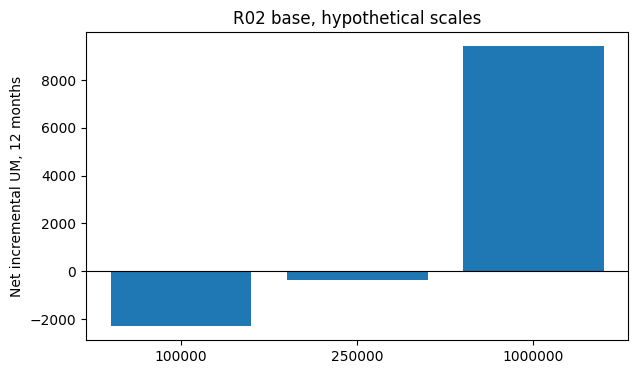

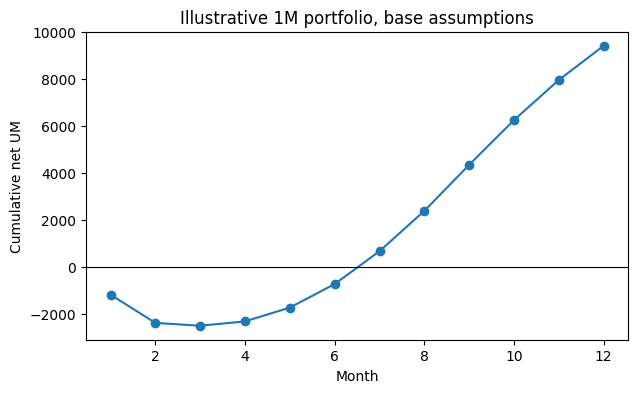

In [10]:
subprocess.run([sys.executable,str(root/'tools/verify_aggregate.py')],cwd=root,check=True)
sc=table('economics/results/scenarios.csv'); show(sc,['scenario','N','incremental_saves_recognized','additional_active_end','revenue_delta','margin_delta','build','run','net','npv','roi','payback'])
base=[r for r in sc if r['scenario']=='Base']; b=base[0]; print('NPV break-even scale (fixed own cost, proportional capacity):',float(b['N'])*float(b['pv_cost'])/float(b['pv_benefit']))
if plt:
    fig,ax=plt.subplots(figsize=(7,4)); ax.bar([r['N'] for r in base],[float(r['net']) for r in base]);ax.axhline(0,color='black',lw=.8);ax.set(ylabel='Net incremental UM, 12 months',title='R02 base, hypothetical scales');plt.show()
    rows=[r for r in table('economics/results/monthly.csv') if r['scenario']=='Base' and int(r['N'])==1000000];fig,ax=plt.subplots(figsize=(7,4));ax.plot([int(r['month']) for r in rows],[float(r['cumulative']) for r in rows],marker='o');ax.axhline(0,color='black',lw=.8);ax.set(xlabel='Month',ylabel='Cumulative net UM',title='Illustrative 1M portfolio, base assumptions');plt.show()

## 7. Decision and validation plan (slide 14)
Recommend readiness and a bounded randomized pilot, not rollout. P0: verify BAU, temporal semantics, consent, capacity, margin and costs. P1: action versus control, measure ITT churn, persistence, harm and incentives. P2: matched policies at equal capacity and same business lane, randomized before selection. Evaluate margin per eligible and per hour; require causal evidence, operational guardrails and positive marginal NPV at actual scale. No sample size invented.

## 8. Original executable analytical source (authorized development only)
The following cells stage the unmodified development code in the temporary workspace. Reading the source is safe; running the optional path requires the authorized original ZIPs and pinned historical model environment. No reserve evaluation script is included. The archived F3 full-sample audit is represented by frozen aggregates, not rerun. The original F5 script and Q0062 development recipe reconstruct the EDA, features, OOF calibration and internal-validation prediction vector. No new candidate search or holdout scoring is triggered.

### `tools/prepare_private_inputs.py`

In [11]:
write('tools/prepare_private_inputs.py', r'''
"""Copy only original development-recipe dependencies from the private master archive.
No model fitting, raw data extraction, or reserve evaluation. Never commit the target folder.
"""
from pathlib import Path
import argparse, hashlib, json, zipfile, shutil
p=argparse.ArgumentParser();p.add_argument("master_zip",type=Path);p.add_argument("--work-dir",type=Path,default=Path("private_work"));a=p.parse_args()
root=Path(__file__).resolve().parents[1]; deps=json.loads((root/"model/private_dependencies.json").read_text())
if a.work_dir.exists():raise SystemExit("Choose a new work directory; never overwrite the archive or existing run.")
shutil.copytree(root/"model",a.work_dir)
with zipfile.ZipFile(a.master_zip) as z:
    for rel,expected in deps.items():
        names=[n for n in z.namelist() if n.endswith("/repositorio/"+rel)]
        if len(names)!=1:raise ValueError(f"Expected one exact dependency: {rel}, got {names}")
        b=z.read(names[0]); assert hashlib.sha256(b).hexdigest()==expected, rel
        out=a.work_dir/rel;out.parent.mkdir(parents=True,exist_ok=True);out.write_bytes(b)
print("Private dependency hashes verified. No training or reserve evaluation performed.")
'''[1:])

### `operations/gestion_hibrida.py`

In [12]:
write('operations/gestion_hibrida.py', r'''
"""Illustrative operational queue allocator, no customer data. 75/25 applies to minutes and slots.
Run python gestion_hibrida.py; writes synthetic QA and capacity scenarios. Not production CRM.
"""
from pathlib import Path
import pandas as pd, math
D=Path(__file__).resolve().parent/'resultados/cierre'
def allocate(rows,slots,minutes,alpha=.75):
 assert 0<=alpha<=1 and slots>=0 and minutes>=0 and rows.id.is_unique
 # mandatory service handled outside marketing queue; unknown permission fails closed.
 valid=rows[rows.active.eq(True)&rows.consent.eq(True)&rows.optout.eq(False)&rows.cooldown.eq(False)&rows.collision.eq(False)&rows.closed.eq(False)&rows.open_case.eq(False)&rows.valid_action.eq(True)&rows.minutes.gt(0)].copy()
 used=set();chosen=[]; left={'analytics':[math.floor(slots*alpha),minutes*alpha],'business':[slots-math.floor(slots*alpha),minutes*(1-alpha)]}
 def take(candidates,lane,quota):
  for x in candidates.itertuples():
   if x.id in used or quota[0]<1 or quota[1]<x.minutes:continue
   quota[0]-=1;quota[1]-=x.minutes;used.add(x.id);chosen.append(dict(id=x.id,lane=lane,minutes=x.minutes,reason=x.reason if lane=='business' else 'model_rank',score=x.score))
 # reserve explicit business commitments/campaigns first; do not count same person twice.
 take(valid[valid.business.eq(True)&valid.reason.notna()].sort_values(['business_priority','id'],ascending=[False,True]),'business',left['business'])
 ranked=valid[valid.score.notna()].sort_values(['score','id'],ascending=[False,True]);take(ranked,'analytics',left['analytics'])
 # release only unused business quota to analytics, not silently oversubscribe
 take(ranked,'analytics_backfill',left['business']);out=pd.DataFrame(chosen)
 if len(out):assert out.id.is_unique and len(out)<=slots and out.minutes.sum()<=minutes+1e-9 and set(out.id)<=set(valid.id)
 return out
if __name__=='__main__':
 rows=pd.DataFrame([dict(id=f'C{i:02}',score=100-i,active=True,consent=True,optout=i==0,cooldown=i==1,collision=i==2,closed=i==3,open_case=i==4,valid_action=i!=5,minutes=10,business=i in [6,12,13],business_priority=100-i,reason='callback' if i==6 else 'campaign' if i in [12,13] else None) for i in range(20)])
 out=allocate(rows,8,80);assert len(out)==8 and not set(out.id)&set(rows.id[:6]);assert (out.lane=='business').sum()==2;out.to_csv(D/'synthetic_hybrid_queue.csv',index=False)
 res=[]
 for N in [100000,250000,1000000]:
  for k in [.05,.1,.2,.3]:
   eligible=int(N*.8);slots=int(eligible*k);demand=slots*.3;human_cap=20*30*60/10
   res.append(dict(portfolio=N,eligible=eligible,k=k,selected=slots,analytics_slots=int(.75*slots),business_slots=slots-int(.75*slots),human_share=.3,human_demand=int(demand),human_capacity=int(human_cap),human_gap=int(max(demand-human_cap,0)),required_hours=demand*10/60,available_hours=600))
 pd.DataFrame(res).to_csv(D/'capacity_hybrid_scenarios.csv',index=False);print('synthetic allocation tests PASS')
'''[1:])

### `model/diagnostico/fase5/src/eda_f5.py`

In [13]:
write('model/diagnostico/fase5/src/eda_f5.py', r'''
import argparse, csv, io, hashlib, json, zipfile, platform
from pathlib import Path
import numpy as np, pandas as pd
from scipy.stats import spearmanr, chi2_contingency
from sklearn.model_selection import train_test_split
from docx import Document
P=argparse.ArgumentParser();P.add_argument('--source',required=True);P.add_argument('--master',required=True);P.add_argument('--out',required=True);a=P.parse_args();o=Path(a.out);o.mkdir(parents=True,exist_ok=True)
with zipfile.ZipFile(a.master) as z:
 def get(s):return z.read(next(n for n in z.namelist() if n.endswith(s)))
 manifest=get('/preliminar/resultados/split_manifest.csv'); old=json.loads(get('/preliminar/resultados/audit.json'))
# Only store development IDs; never compute reserve statistics or read reserve labels.
m=pd.read_csv(io.BytesIO(manifest)); dev=set(m.loc[m.partition.eq('exploratory'),'Customer_ID']);assert len(dev)==70000 and m.Customer_ID.is_unique;del m
with zipfile.ZipFile(a.source) as z:
 tables=[]; hashes={}
 for name in ['Client','Record']:
  member=next(n for n in z.namelist() if n.endswith('/'+name+'.csv')); h=hashlib.sha256(); buf=io.BytesIO()
  with z.open(member) as f:
   header=f.readline();h.update(header);assert header.decode().strip().split(',')[-1]=='Customer_ID';buf.write(header)
   for line in f:
    h.update(line) # integrity only, no reserve field parsing except key
    key=int(line.rstrip(b'\r\n').rsplit(b',',1)[-1]);
    if key in dev:buf.write(line)
  hashes[name]=h.hexdigest();assert hashes[name]==old[name]['sha256'];buf.seek(0);t=pd.read_csv(buf);assert len(t)==70000 and t.Customer_ID.is_unique and set(t.Customer_ID)==dev;tables.append(t)
 d=tables[0].merge(tables[1],on='Customer_ID',validate='one_to_one').sort_values('Customer_ID').reset_index(drop=True)
 doc=Document(io.BytesIO(z.read(next(n for n in z.namelist() if n.endswith('Dataset Overview.docx')))));dictionary={r.cells[0].text.strip():r.cells[1].text.strip() for t in doc.tables for r in t.rows[1:] if len(r.cells)==2}
assert d.shape==(70000,100) and set(d.churn)=={0,1} and d.churn.notna().all()
y=d.churn; rev=d.rev_Mean; v=rev.clip(lower=0); known=rev.notna();base=y.mean();den=(v*y).sum()
def wilson(k,n):
 if n==0:return (np.nan,np.nan)
 p=k/n;z=1.96;mid=(p+z*z/(2*n))/(1+z*z/n);half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n);return mid-half,mid+half
au=dict(n=len(d),columns=len(d.columns),target_1=int(y.sum()),target_0=int((1-y).sum()),churn_share=base,missing_cells=int(d.isna().sum().sum()),complete_rows=int(d.notna().all(axis=1).sum()),missing_cols=int(d.isna().any().sum()),revenue_missing=int(rev.isna().sum()),negative_revenue=int((rev<0).sum()),zero_revenue=int((rev==0).sum()),negative_equipment=int((d.eqpdays<0).sum()),zero_attempts=int((d.attempt_Mean==0).sum()),active_gt_unique=int((d.actvsubs>d.uniqsubs).sum()),revenue_positive_sum=float(v.sum()),churn_revenue_positive_sum=float(den),revenue_known_mean=float(rev.mean()),hashes=hashes,manifest_sha256=hashlib.sha256(manifest).hexdigest(),reserve='not parsed except IDs for selection; bytes hashed for integrity; prior aggregate inspection F3',python=platform.python_version(),pandas=pd.__version__,numpy=np.__version__)
(o/'audit.json').write_text(json.dumps(au,indent=2))
# Every original field, with conservative feature eligibility classifications.
excluded={'Customer_ID','churn','recv_sms_Mean','iwylis_vce_Mean'}
profile_fields={'prizm_social_one','area','truck','rv','ownrent','lor','dwlltype','marital','adults','infobase','income','numbcars','HHstatin','dwllsize','forgntvl','ethnic','kid0_2','kid3_5','kid6_10','kid11_15','kid16_17','creditcd','crclscod','asl_flag'}
conditional={'totcalls','totmou','totrev','adjrev','adjmou','adjqty','avgrev','avgmou','avgqty','months','eqpdays','phones','models','uniqsubs','actvsubs','new_cell','hnd_price','dualband','refurb_new','hnd_webcap'}
rows=[]; levels=[]; features=[]
for c in d:
 s=d[c];missing=s.isna();num=pd.api.types.is_numeric_dtype(s); r=dict(variable=c,dtype=str(s.dtype),missing_n=int(missing.sum()),missing_pct=missing.mean()*100,unique=s.nunique(),churn_missing=y[missing].mean(),churn_present=y[~missing].mean())
 if num:
  q=s.quantile([0,.01,.25,.5,.75,.95,.99,1]);r.update({k:float(val) for k,val in zip(['min','p01','p25','median','p75','p95','p99','max'],q)});r.update(mean=s.mean(),zeros=int(s.eq(0).sum()),negatives=int(s.lt(0).sum()),iqr_outliers=int(((s<q[.25]-1.5*(q[.75]-q[.25]))|(s>q[.75]+1.5*(q[.75]-q[.25]))).sum()),spearman_churn=s.corr(y,method='spearman') if c not in ['Customer_ID','churn'] and s.nunique()>1 else np.nan,mean_churn=s[y.eq(1)].mean(),mean_stay=s[y.eq(0)].mean())
 elif c not in excluded:
  for k,g in d.groupby(s.fillna('[missing]')):
   if len(g)>=30: levels.append(dict(variable=c,level=k,n=len(g),churn=g.churn.mean(),mean_revenue=g.rev_Mean.mean()))
 rows.append(r)
 desc=dictionary.get(c,'Not documented');status='exclude' if c in excluded else 'audit_only' if c in profile_fields else 'conditional_snapshot' if c in conditional else 'candidate_unverified'
 timing='target days 31–60' if c=='churn' else 'key only' if c=='Customer_ID' else 'undefined' if desc in ['NaN','Not documented'] else 'prior 3/6 months, exact cutoff unconfirmed' if c.startswith(('avg3','avg6','change_')) else 'lifetime/snapshot cutoff unconfirmed' if c in conditional else 'aggregation period/cutoff unconfirmed' if c.endswith('_Mean') else 'snapshot cutoff unconfirmed'
 features.append(dict(variable=c,definition=desc,timing=timing,status=status,missing_n=int(missing.sum()),rule='never predictor' if status=='exclude' else 'no production targeting; governance review' if status=='audit_only' else 'confirm as-of t0; train-fold transforms; exclude in conservative ablation if cutoff unverified'))
pd.DataFrame(rows).to_csv(o/'field_profile.csv',index=False);pd.DataFrame(levels).to_csv(o/'categorical_profiles.csv',index=False);pd.DataFrame(features).to_csv(o/'feature_register.csv',index=False)
# Fixed, interpretable cuts inherited where feasible. Missing/invalid separated.
def cut(s,bins,labels):return pd.cut(s,bins,labels=labels,include_lowest=True).astype('object').fillna('Missing/invalid')
ratio=d.drop_blk_Mean.div(d.attempt_Mean.where(d.attempt_Mean>=30));ratio=ratio.where(ratio.between(0,1));eq=d.eqpdays.where(d.eqpdays>=0)
seg={ 'tenure_months':cut(d.months,[0,6,12,24,36,np.inf],['0–6','7–12','13–24','25–36','37+']), 'equipment_days':cut(eq,[0,180,365,730,np.inf],['0–180','181–365','366–730','731+']), 'revenue':cut(v,[-.001,25,50,75,100,150,np.inf],['0–25','25–50','50–75','75–100','100–150','150+']), 'usage_minutes':cut(d.mou_Mean,[-.001,100,300,600,1000,np.inf],['0–100','100–300','300–600','600–1000','1000+']), 'change_usage':cut(d.change_mou,[-np.inf,-50,0,50,np.inf],['≤−50','−50–0','0–50','>50']), 'care_calls':cut(d.custcare_Mean,[-.001,0,1,3,np.inf],['0','0–1','1–3','>3']), 'failure_ratio':cut(ratio,[-.001,.02,.05,.10,.20,1],['0–2%','2–5%','5–10%','10–20%','20–100%']), 'overage':cut(d.ovrrev_Mean,[-.001,0,20,50,np.inf],['0','0–20','20–50','50+']), 'active_subscribers':cut(d.actvsubs,[0,1,2,3,np.inf],['0–1','2','3','4+']) }
def summarize(g):
 n=int(np.sum(g));k=int(y[g].sum());lo,hi=wilson(k,n);return dict(n=n,churn_n=k,churn_rate=k/n,ci_low=lo,ci_high=hi,rev_known=int(known[g].sum()),mean_revenue=v[g].mean(),revenue_sum=v[g].sum(),churn_revenue=(v[g]*y[g]).sum(),exposure_share=(v[g]*y[g]).sum()/den)
ss=[]
for name,s in seg.items():
 for k in s.unique():ss.append(dict(segment=name,level=k,**summarize(s.eq(k))))
pd.DataFrame(ss).to_csv(o/'segments.csv',index=False)
# associations with controls (not causal), common support counts; missing separated from controls
rules={'H1_old_equipment':(eq.ge(730),eq.notna()),'H2_usage_decline':(d.change_mou.lt(0),d.change_mou.notna()),'H3_failure_ge10pct':(ratio.ge(.1),ratio.notna()),'H4_care_ge3':(d.custcare_Mean.ge(3),d.custcare_Mean.notna()),'H5_overage_ge20':(d.ovrrev_Mean.ge(20),d.ovrrev_Mean.notna()),'H6_revenue_ge100':(rev.ge(100),known),'H7_multi_active':(d.actvsubs.ge(2),d.actvsubs.notna()),'H8_revenue100_old':(rev.ge(100)&eq.ge(730),known&eq.notna()),'H9_decline_old':(d.change_mou.lt(0)&eq.ge(730),d.change_mou.notna()&eq.notna()),'H10_decline_overage':(d.change_mou.lt(0)&d.ovrrev_Mean.ge(20),d.change_mou.notna()&d.ovrrev_Mean.notna())}
rr=[];strata=[];masks={};sens=[]
for name,(m,e) in rules.items():
 m=m&e;ctrl=(~m)&e;g=summarize(m);h=summarize(ctrl);gap=g['churn_rate']-h['churn_rate'];se=np.sqrt(g['churn_rate']*(1-g['churn_rate'])/g['n']+h['churn_rate']*(1-h['churn_rate'])/h['n']);total=weighted=0
 for (tb,ub),ix in d[e].groupby([seg['tenure_months'],seg['usage_minutes']]).groups.items():
  # tenure is definitionally linked to equipment; conditioning is descriptive only
  a1=y.loc[ix][m.loc[ix]];a0=y.loc[ix][ctrl.loc[ix]]
  if min(len(a1),len(a0))>=30:
   delta=a1.mean()-a0.mean();total+=len(ix);weighted+=len(ix)*delta;strata.append(dict(rule=name,tenure=tb,usage=ub,n=len(ix),exposed=len(a1),gap_pp=100*delta))
 rr.append(dict(rule=name,eligible_n=int(e.sum()),**g,control_n=h['n'],control_rate=h['churn_rate'],gap_pp=gap*100,ci_low_pp=(gap-1.96*se)*100,ci_high_pp=(gap+1.96*se)*100,standardized_gap_pp=100*weighted/total if total else np.nan,common_support=total/e.sum()));masks[name]=m
 for p in [.005,.01,.02,base]:
  w=pd.Series(np.where(y==1,p/base,(1-p)/(1-base)));sel=w[m].sum();sens.append(dict(rule=name,prior=p,selected_per_1000=1000*sel/w.sum(),precision=(w[m]*y[m]).sum()/sel,exposure_per_1000=1000*(w[m]*y[m]*v[m]).sum()/w.sum(),rev_coverage_weighted=w[m&known].sum()/sel))
pd.DataFrame(rr).to_csv(o/'hypotheses.csv',index=False);pd.DataFrame(strata).to_csv(o/'strata.csv',index=False);pd.DataFrame(sens).to_csv(o/'prior_scenarios.csv',index=False);b=pd.DataFrame(masks).astype(int);b.T.dot(b).to_csv(o/'overlap.csv')
# Interactions: value x equipment, change x overage; all levels retained, no cherry-pick
out=[]
for f,g in [('revenue','equipment_days'),('change_usage','overage'),('failure_ratio','care_calls')]:
 for (i,j),ix in d.groupby([seg[f],seg[g]]).groups.items():
  mask=d.index.isin(ix);out.append(dict(dim1=f,level1=i,dim2=g,level2=j,**summarize(mask)))
pd.DataFrame(out).to_csv(o/'interactions.csv',index=False)
# Semantic checks: do documented percentage changes resemble absolute deviations? no redefinition without client.
checks={}
for c,cur,prev in [('change_mou','mou_Mean','avg3mou'),('change_rev','rev_Mean','avg3rev')]:
 t=d[[c,cur,prev]].dropna();t=t[t[prev]>0];diff=t[cur]-t[prev];pct=100*diff/t[prev];checks[c]={'n':len(t),'corr_absolute':float(t[c].corr(diff)),'corr_percentage':float(t[c].corr(pct)),'sign_match_absolute':float((np.sign(t[c])==np.sign(diff)).mean())}
checks['failure_ratio']={'valid_n':int(ratio.notna().sum()),'above_one_before_filter':int((d.drop_blk_Mean.div(d.attempt_Mean.where(d.attempt_Mean>=30))>1).sum())};checks['device_age_vs_tenure_approx']={'older_than_months_x31':int((eq>d.months*31).sum())};checks['id_order_diagnostic']=[dict(decile=i+1,n=len(g),churn=g.churn.mean()) for i,g in enumerate(np.array_split(d[['churn']],10))]
(o/'semantic_checks.json').write_text(json.dumps(checks,indent=2))
# Proposed split only. Reuses F3 seed and explicitly labels both development partitions as explored.
tr,va=train_test_split(d.Customer_ID,test_size=.25,random_state=20261125,stratify=y);assert set(tr).isdisjoint(va) and len(tr)==52500 and len(va)==17500
assert np.array_equal(tr.to_numpy(), d.Customer_ID.iloc[train_test_split(np.arange(len(d)),test_size=.25,random_state=20261125,stratify=y)[0]].to_numpy())
# No identifiers in delivered tables. Recreate split from original manifest and this script; store digests only.
(o/'split_proposal.json').write_text(json.dumps({'seed':20261125,'method':'stratified random on ID-sorted development only','train_n':len(tr),'validation_n':len(va),'train_ids_sha256':hashlib.sha256(','.join(map(str,sorted(tr))).encode()).hexdigest(),'validation_ids_sha256':hashlib.sha256(','.join(map(str,sorted(va))).encode()).hexdigest(),'note':'proposed reuse of exact F3 algorithm, ID order, seed and labels; all development labels already explored; not clean holdout'},indent=2))
# Revenue concentration and redundant signals; descriptive only.
conc=[]
ranked=d.loc[rev.ge(0)].sort_values(['rev_Mean','Customer_ID'],ascending=[False,True]);total_valid=ranked.rev_Mean.sum();total_exp=(ranked.rev_Mean*ranked.churn).sum()
for frac in [.01,.05,.10,.20,.50]:
 g=ranked.head(int(np.ceil(frac*len(ranked))));conc.append(dict(top_fraction=frac,n=len(g),revenue_share=g.rev_Mean.sum()/total_valid,churn_rate=g.churn.mean(),exposure_share=(g.rev_Mean*g.churn).sum()/total_exp))
pd.DataFrame(conc).to_csv(o/'revenue_concentration.csv',index=False)
cols=[c for c in d.select_dtypes('number') if c not in excluded and c not in profile_fields];corr=d[cols].corr(method='spearman');pairs=[]
for i,c in enumerate(cols):
 for j in range(i):
  val=corr.iloc[i,j]
  if abs(val)>=.95:pairs.append(dict(feature1=c,feature2=cols[j],spearman=val))
pd.DataFrame(pairs).sort_values('spearman',ascending=False).to_csv(o/'redundant_pairs.csv',index=False)
# QA: reconcile each partition, exposure and counts; prevent boolean-length denominator bug.
segdf=pd.DataFrame(ss);assert (segdf.groupby('segment').n.sum()==len(d)).all() and (segdf.groupby('segment').churn_n.sum()==y.sum()).all() and np.allclose(segdf.groupby('segment').exposure_share.sum(),1)
for row in rr:assert row['n']+row['control_n']==row['eligible_n'] and row['n']>=row['churn_n'] and 0<=row['churn_rate']<=1
assert (pd.DataFrame(rr).n.to_numpy()==np.diag(b.T.dot(b))).all()
(o/'qa.json').write_text(json.dumps({'status':'PASS','checks':['source SHA256 matches F3','unique development IDs both tables and 1:1 join','target binary complete','all nine segment partitions reconcile count, churn and exposure','rule denominators and overlap diagonal reconcile','split matches F3 algorithm and disjoint sizes'],'limitations':'Arithmetic and provenance only; not validation of commercial assumptions or temporal leakage.'},indent=2))
print(json.dumps(au,indent=2));print(pd.DataFrame(rr)[['rule','n','churn_rate','gap_pp','standardized_gap_pp','common_support','churn_revenue','exposure_share']].round(4).to_string(index=False));print(json.dumps(checks,indent=2))
'''[1:])

### `model/diagnostico/fase6/corte05/base.py`

In [14]:
write('model/diagnostico/fase6/corte05/base.py', r'''
import os
os.environ.update(OMP_NUM_THREADS='4',OPENBLAS_NUM_THREADS='1',MKL_NUM_THREADS='1')
import sys,io,zipfile,hashlib,json,time
from pathlib import Path
import numpy as np,pandas as pd,sklearn,lightgbm as lgb,joblib
from sklearn.model_selection import train_test_split,StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score,average_precision_score,brier_score_loss,log_loss
from scipy.special import expit,logit
P=Path(__file__).resolve().parent;R=P.parents[2];O=P/'results';O.mkdir(exist_ok=True)
if '--reproduce' in sys.argv:
 import shutil
 frozen=O;O=P/'reproduction';O.mkdir(exist_ok=True)
 for f in ['candidate_recipes.json','calibrated_cv_rank.csv']:shutil.copy2(frozen/f,O/f)
 sys.argv.extend(['--recipe','--champion-only','--rebuild-oof'])

sha=lambda b:hashlib.sha256(b).hexdigest();manifest=(R/'diagnostico/fase3/preliminar/resultados/split_manifest.csv').read_bytes();m=pd.read_csv(io.BytesIO(manifest));ids=set(m.loc[m.partition.eq('exploratory'),'Customer_ID']);assert len(ids)==70000 and m.Customer_ID.is_unique;del m
old=json.loads((R/'diagnostico/fase3/preliminar/resultados/audit.json').read_text());f5=R/'diagnostico/fase5/resultados';audit=json.loads((f5/'audit.json').read_text());assert sha(manifest)==audit['manifest_sha256'];tables=[];hashes={}
with zipfile.ZipFile(sys.argv[1]) as z:
 for name in ['Client','Record']:
  h=hashlib.sha256();b=io.BytesIO()
  with z.open(next(n for n in z.namelist() if n.endswith('/'+name+'.csv'))) as f:
   header=f.readline();h.update(header);assert header.decode().strip().split(',')[-1]=='Customer_ID';b.write(header)
   for line in f:
    h.update(line);key=int(line.rstrip(b'\r\n').rsplit(b',',1)[-1]);
    if key in ids:b.write(line)
  hashes[name]=h.hexdigest();assert hashes[name]==old[name]['sha256'];b.seek(0);t=pd.read_csv(b);assert len(t)==70000 and t.Customer_ID.is_unique and set(t.Customer_ID)==ids;tables.append(t)
d=tables[0].merge(tables[1],on='Customer_ID',validate='one_to_one').sort_values('Customer_ID').reset_index(drop=True);y=d.churn.to_numpy(int);rev=d.rev_Mean.to_numpy();assert d.shape==(70000,100)
tr,va=train_test_split(np.arange(len(d)),test_size=.25,random_state=20261125,stratify=y);prop=json.loads((f5/'split_proposal.json').read_text());hi=lambda a:sha(','.join(map(str,sorted(a))).encode());print("split hashes",hi(tr),hi(va),prop,flush=True);assert hi(d.Customer_ID.iloc[tr])==prop['train_ids_sha256'] and hi(d.Customer_ID.iloc[va])==prop['validation_ids_sha256'];assert not set(tr)&set(va)
folds=list(StratifiedKFold(5,shuffle=True,random_state=20261126).split(tr,y[tr]));foldid=np.full(len(tr),-1)
for j,(_,b) in enumerate(folds):foldid[b]=j
pd.DataFrame({'Customer_ID':d.Customer_ID.iloc[tr],'fold':foldid}).to_csv(O/'train_manifest.csv',index=False);pd.DataFrame({'Customer_ID':d.Customer_ID.iloc[va]}).to_csv(O/'validation_manifest.csv',index=False)
tie=np.random.default_rng(20261127).permutation(len(d));q=y[tr].mean();(O/'integrity.json').write_text(json.dumps(dict(source_hashes=hashes,manifest_hash=sha(manifest),position_hashes=[hi(tr),hi(va)],actual_id_hashes=[hi(d.Customer_ID.iloc[a]) for a in [tr,va]],n_train=len(tr),n_valid=len(va),train_churn=int(y[tr].sum()),valid_churn=int(y[va].sum()),eligible_train=int(np.sum(np.isfinite(rev[tr])&(rev[tr]>=0))),eligible_valid=int(np.sum(np.isfinite(rev[va])&(rev[va]>=0))),fold_sizes=[len(b) for _,b in folds],reserve='keys only for filtering, bytes hashed; no fields parsed',sklearn=sklearn.__version__,lightgbm=lgb.__version__,numpy=np.__version__,pandas=pd.__version__),indent=2))
reg=pd.read_csv(f5/'feature_register.csv');allowed=reg.loc[~reg.status.isin(['audit_only','exclude']),'variable'].tolist();base=['rev_Mean','mou_Mean','totmrc_Mean','ovrrev_Mean','change_mou','change_rev','avg3mou','avg3rev','avg6mou','avg6rev','months','eqpdays','phones','custcare_Mean','drop_blk_Mean','attempt_Mean'];assert set(base)<=set(allowed)
x=d[allowed].copy();x['rev_Mean']=x.rev_Mean.where(x.rev_Mean>=0);x['eqpdays']=x.eqpdays.where(x.eqpdays>=0);num=x.select_dtypes('number').columns.tolist();cur=[c for c in num if c not in ['change_mou','change_rev']];basic=[c for c in base if c not in ['change_mou','change_rev']];no_snap=[c for c in cur if reg.set_index('variable').loc[c,'status']!='conditional_snapshot'];eng=x[cur].copy()
for name,a,b in [('usage_delta','mou_Mean','avg3mou'),('rev_delta','rev_Mean','avg3rev'),('usage_trend','avg3mou','avg6mou'),('rev_trend','avg3rev','avg6rev')]:
 eng[name]=x[a]-x[b];eng[name+'_relative']=eng[name]/x[b].where(x[b]>0)
for name,a,b,minb in [('failure','drop_blk_Mean','attempt_Mean',30),('overage_share','ovrrev_Mean','rev_Mean',1e-9),('care_minutes_per_call','cc_mou_Mean','custcare_Mean',1e-9),('device_tenure','eqpdays','months',1)]:eng[name]=x[a]/x[b].where(x[b]>=minb)
eng['failure']=eng.failure.where(eng.failure.between(0,1));eng['device_tenure']/=30.4375;eng['decline_sign']=np.sign(x.change_mou);eng['revenue_sign']=np.sign(x.change_rev);eng['old_x_decline']=(x.eqpdays/365)*(-eng.decline_sign);eng['overage_x_decline']=eng.overage_share*(-eng.decline_sign);eng=eng.replace([np.inf,-np.inf],np.nan)
sets={'f3':x[base],'basic':x[basic],'wide':x[cur],'engineered':eng,'no_ambiguous':eng.drop(columns=['decline_sign','revenue_sign','old_x_decline','overage_x_decline']),'no_snapshot':x[no_snap],'log_engineered':np.sign(eng)*np.log1p(np.abs(eng))};(O/'features.json').write_text(json.dumps({k:list(v.columns) for k,v in sets.items()},indent=2))
def corrected(p,prior):return expit(logit(np.clip(p,1e-7,1-1e-7))+logit(prior)-logit(q))
def selection(idx,score,prior=.01,k=.05,counts=None):
 yy=y[idx];rr=rev[idx];ok=np.isfinite(rr)&(rr>=0);yy=yy[ok];rr=rr[ok];ss=np.asarray(score)[ok];tt=tie[idx][ok];cc=np.ones(len(yy)) if counts is None else counts[ok];qq=np.average(yy,weights=cc);w=cc*np.where(yy==1,prior/qq,(1-prior)/(1-qq));order=np.lexsort((tt,-np.nan_to_num(ss,nan=-1e30,neginf=-1e30)));w=w[order];yy=yy[order];rr=rr[order];tot=w.sum();z=np.minimum(w,np.maximum(0,k*tot-(np.cumsum(w)-w)));tp=(z*yy).sum();e=(z*yy*rr).sum();return dict(exposure=1000*e/tot,precision=tp/z.sum(),recall=tp/(w*yy).sum(),lift=tp/z.sum()/prior,exposure_recall=e/(w*yy*rr).sum(),capacity=z.sum()/tot)
def metrics(idx,p):
 yy=y[idx];return dict(auc=roc_auc_score(yy,p),ap=average_precision_score(yy,p),brier=brier_score_loss(yy,p),logloss=log_loss(yy,p))
def scores(idx,p,prior=.01,alpha=1):return corrected(p,prior)**alpha*np.nan_to_num(np.maximum(rev[idx],0))
def simple(idx):return {'B1_revenue':rev[idx],'B2_decline':-d.change_mou.iloc[idx].fillna(np.inf).to_numpy(),'B3_device':d.eqpdays.iloc[idx].where(d.eqpdays.iloc[idx]>=0,-np.inf).fillna(-np.inf).to_numpy()}
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesClassifier,HistGradientBoostingClassifier
from sklearn.preprocessing import QuantileTransformer
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
new=sets['no_ambiguous'].copy()
for a,b in [('avg3qty','avg6qty'),('avg3mou','avgmou'),('avg3rev','avgrev'),('avg3qty','avgqty'),('mou_Mean','avgmou'),('rev_Mean','avgrev'),('avg6mou','avgmou'),('avg6rev','avgrev'),('avgmou','avgqty'),('avg3mou','avg3qty'),('mou_Mean','attempt_Mean'),('mou_cvce_Mean','comp_vce_Mean'),('ovrmou_Mean','mou_Mean'),('totmrc_Mean','rev_Mean'),('roam_Mean','attempt_Mean'),('complete_Mean','attempt_Mean'),('custcare_Mean','attempt_Mean'),('mou_peav_Mean','mou_Mean'),('actvsubs','uniqsubs'),('phones','months'),('models','phones'),('totrev','months'),('totmou','months'),('adjrev','totrev')]:new[a+'__per__'+b]=x[a]/x[b].where(x[b]>0)
for a,b in [('avg3qty','avg6qty'),('avg3qty','avgqty'),('avg3mou','avgmou'),('avg3rev','avgrev'),('totrev','adjrev'),('totmou','adjmou'),('totcalls','adjqty'),('rev_Mean','totmrc_Mean'),('phones','models'),('uniqsubs','actvsubs')]:new[a+'__minus__'+b]=x[a]-x[b]
new['tenure_minus_device_days']=x.months*30.4375-x.eqpdays
new['current_vs_old3_mou']=x.mou_Mean-(2*x.avg6mou-x.avg3mou)
new['current_vs_old3_rev']=x.rev_Mean-(2*x.avg6rev-x.avg3rev)
new['current_vs_old3_qty']=x.attempt_Mean-(2*x.avg6qty-x.avg3qty)
sets['mechanism']=new.replace([np.inf,-np.inf],np.nan);catcols=[c for c in allowed if c not in num];print('categories',catcols,flush=True)
sets['cat']=pd.concat([sets['mechanism'],x[catcols].fillna('__MISSING__').astype(str)],axis=1)
sets['raw_change']=sets['mechanism'].assign(change_mou=x.change_mou,change_rev=x.change_rev)
sets['recent']=x[no_snap].copy()
for c in ['usage_delta','rev_delta','usage_trend','rev_trend','usage_delta_relative','rev_delta_relative','usage_trend_relative','rev_trend_relative','failure','overage_share','care_minutes_per_call']:sets['recent'][c]=eng[c]
# Additional mechanistic interactions: no identifiers or protected attributes.
plus=sets['mechanism'].copy()
for a,b in [('mou_Mean','avg3mou'),('rev_Mean','avg3rev'),('attempt_Mean','avg3qty')]:
 plus[a+'__recent4_vs_3']=4*(x[a]-x[b]);plus[a+'__recent4_relative']=4*(x[a]-x[b])/x[b].where(x[b]>0)
for a,b in [('avgmou','avg6mou'),('avgrev','avg6rev'),('avgqty','avg6qty')]:plus[a+'__older_life']=(x[a]*x.months-6*x[b])/(x.months-6).where(x.months>6)
plus['failure_x_decline']=eng.failure*eng.usage_delta_relative
plus['overage_x_decline']=eng.overage_share*eng.usage_delta_relative
plus['device_x_decline']=x.eqpdays*eng.usage_delta_relative
plus['tenure_x_decline']=x.months*eng.usage_delta_relative
plus['rev_x_usage_decline']=x.rev_Mean*eng.usage_delta_relative
sets['plus']=plus.replace([np.inf,-np.inf],np.nan)
life=['totcalls','totmou','totrev','adjrev','adjmou','adjqty','avgrev','avgmou','avgqty']
sets['no_lifetime']=sets['mechanism'].drop(columns=[c for c in sets['mechanism'] if any(t in c.split('__') for t in life)])
sets['raw_revenue']=sets['mechanism'].copy();sets['raw_revenue']['rev_Mean']=d.rev_Mean
configs={}
def add(n,f,s,**p):configs[n]=dict(name=n,family=f,features=s,params=p)
def lg(n,s,leaves,depth,nest,lr,child):add(n,'lgb',s,num_leaves=leaves,max_depth=depth,n_estimators=nest,learning_rate=lr,min_child_samples=child)
lg('C01_Tdeep','no_ambiguous',31,7,80,.1,80)
lg('LGB_mech','mechanism',31,8,120,.08,70)
add('XGB_6','xgb','mechanism',max_depth=6,n_estimators=120,learning_rate=.085,min_child_weight=12,subsample=.85,colsample_bytree=.85,reg_lambda=4)
add('CAT_6','cat','cat',depth=6,iterations=150,learning_rate=.1,l2_leaf_reg=5)
lg('LGB_cat','cat',31,8,120,.08,70)
lg('LGB_63','mechanism',63,10,160,.065,45)
lg('LGB_200','no_ambiguous',31,8,200,.05,60)
lg('LGB_raw_change','raw_change',31,8,120,.08,70)
lg('LGB_recent','recent',31,7,120,.08,80)
lg('LGB_shallow','cat',15,5,220,.06,100)
add('XGB_4','xgb','cat',max_depth=4,n_estimators=180,learning_rate=.08,min_child_weight=20,subsample=.9,colsample_bytree=.85,reg_lambda=5)
add('ExtraTrees','extra','mechanism',n_estimators=80,max_depth=14,min_samples_leaf=25,max_features=.75)
lg('LGB_plus','plus',63,10,220,.05,50)
lg('LGB_500','mechanism',63,10,400,.035,60)
lg('LGB_no_life','no_lifetime',31,8,160,.065,70)
lg('LGB_raw_revenue','raw_revenue',31,8,120,.08,70)
lg('LGB_revweighted','mechanism',31,8,160,.065,70);configs['LGB_revweighted']['weight']='sqrt_revenue'
add('CAT_8','cat','cat',depth=8,iterations=240,learning_rate=.065,l2_leaf_reg=8)
add('HistGB','hist','mechanism',max_iter=160,max_leaf_nodes=31,learning_rate=.065,l2_regularization=3,min_samples_leaf=60)
add('MLP','mlp','mechanism',hidden_layer_sizes=(64,32),alpha=.01,max_iter=35,early_stopping=True,validation_fraction=.12,batch_size=512,learning_rate_init=.001)
def make(c):
 p=c['params'];f=c['family'];X=sets[c['features']];cats=X.select_dtypes(exclude='number').columns.tolist();nums=X.select_dtypes('number').columns.tolist()
 if f=='cat':return CatBoostClassifier(**p,thread_count=4,random_seed=20261126,verbose=False,allow_writing_files=False,cat_features=cats)
 if f=='lgb':m=lgb.LGBMClassifier(**(dict(random_state=20261126,n_jobs=4,verbosity=-1,reg_lambda=2,feature_fraction=.85)|p))
 elif f=='xgb':m=XGBClassifier(**p,tree_method='hist',n_jobs=4,random_state=20261126,eval_metric='logloss')
 elif f=='hist':m=HistGradientBoostingClassifier(**p,random_state=20261126)
 elif f=='mlp':return make_pipeline(SimpleImputer(strategy='median',add_indicator=True),QuantileTransformer(n_quantiles=300,output_distribution='normal',random_state=20261126),MLPClassifier(**p,random_state=20261126))
 else:return make_pipeline(SimpleImputer(strategy='median',add_indicator=True),ExtraTreesClassifier(**p,n_jobs=4,random_state=20261126))
 if cats:return make_pipeline(ColumnTransformer([('num','passthrough',nums),('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cats)]),m)
 return m
def fit(c,a,b):
 X=sets[c['features']];m=make(c)
 if c.get('weight'):
  r=np.maximum(rev[a],0);r=np.where(np.isfinite(r),r,np.nanmedian(r));w=np.sqrt(np.maximum(r,1));w=np.minimum(w,np.quantile(w,.99));m.fit(X.iloc[a],y[a],sample_weight=w/w.mean())
 else:m.fit(X.iloc[a],y[a])
 return m,m.predict_proba(X.iloc[b])[:,1]
def load_oof(n):
 p=np.zeros(len(tr))
 for j,(_,b) in enumerate(folds):p[b]=np.load(O/f'{n}_fold{j}.npy')
 return p
def calibrate(p,labels):return LogisticRegression(C=100).fit(logit(np.clip(p,1e-7,1-1e-7)).reshape(-1,1),labels)
def applycal(c,p):return c.predict_proba(logit(np.clip(p,1e-7,1-1e-7)).reshape(-1,1))[:,1]
'''[1:])

### `model/diagnostico/fase6/corte05/experiment.py`

In [15]:
write('model/diagnostico/fase6/corte05/experiment.py', r'''
from base import *
from sklearn.preprocessing import SplineTransformer
import warnings
warnings.filterwarnings('ignore',category=UserWarning)
P=Path(__file__).resolve().parent; O=P/'results'; PRE=P.parent/'corte02'/'results'
oldrec=json.loads((PRE/'candidate_recipes.json').read_text());oldcfg=oldrec['configs']
sector={}; defs={}
def put(n,v,desc): sector[n]=v;defs[n]=desc
def rat(a,b,minb=1): return a/b.where(b>=minb)
for t in [12,24]:put(f'tenure_distance_{t}',np.abs(x.months-t),'Distance from hypothetical lifecycle milestone, not contract expiry')
for t in [180,365,730]:put(f'device_distance_{t}',np.abs(x.eqpdays-t),'Distance from hypothetical device age milestone')
for n,a,b in [('tenure',x.months,12),('device',x.eqpdays,365.25)]:
 for f in [np.sin,np.cos]:put(n+'_cycle_'+f.__name__,f(2*np.pi*a/b),'Lifecycle age periodicity, not calendar')
put('device_since_start_days',x.months*30.4375-x.eqpdays,'Approximate previous tenure before current device, conditional snapshot')
for n,a,b in [('voice_failure','drop_vce_Mean','plcd_vce_Mean'),('voice_block','blck_vce_Mean','plcd_vce_Mean'),('data_failure','drop_dat_Mean','plcd_dat_Mean'),('data_block','blck_dat_Mean','plcd_dat_Mean'),('short_inbound','inonemin_Mean','recv_vce_Mean'),('voice_completion','comp_vce_Mean','plcd_vce_Mean'),('wireless_share','mouowylisv_Mean','mou_Mean'),('inwireless_share','mouiwylisv_Mean','mou_Mean'),('peak_share','mou_peav_Mean','mou_Mean')]:
 v=rat(x[a],x[b],10);put(n,v.where(v.between(0,1)),f'{a}/{b}; denominator >=10 and ratio 0–1')
for n,a,b in [('revenue_per_active','rev_Mean','actvsubs'),('usage_per_active','mou_Mean','actvsubs'),('recur_per_active','totmrc_Mean','actvsubs'),('price_per_min','rev_Mean','mou_Mean'),('overage_per_overage_min','ovrrev_Mean','ovrmou_Mean'),('recurring_per_min','totmrc_Mean','mou_Mean'),('outbound_duration','mou_cvce_Mean','comp_vce_Mean'),('inbound_duration','mou_rvce_Mean','recv_vce_Mean'),('handsets_per_month','phones','months'),('callwait_intensity','callwait_Mean','attempt_Mean'),('forward_intensity','callfwdv_Mean','attempt_Mean')]:put(n,rat(x[a],x[b]),f'{a}/{b}; denominator >=1')
for t,a,b,c in [('usage','mou_Mean','avg3mou','avg6mou'),('revenue','rev_Mean','avg3rev','avg6rev')]:
 aa,bb,cc=x[a],x[b],x[c];put(t+'_log_recent',np.log1p(aa.clip(lower=0))-np.log1p(bb.clip(lower=0)),'Log recent vs prior3 contrast; cutoff conditional');put(t+'_log_hist',np.log1p(bb.clip(lower=0))-np.log1p(cc.clip(lower=0)),'Log prior3 vs prior6 contrast; overlapping windows');put(t+'_accel',((aa-bb)-(bb-cc))/(1+cc.abs()),'Normalized contrast of contrasts, not verified acceleration');put(t+'_symmetric',(aa-bb)/(1+aa.abs()+bb.abs()),'Bounded symmetric change');old=2*cc-bb;put(t+'_prior_older3',old.where(old>=0),'Older 3m mean conditional on aligned windows');put(t+'_recent_vs_older3',(bb-old)/(1+bb.abs()+old.abs()).where(old>=0),'Contrast conditional on aligned windows')
put('billing_usage_divergence',sector['revenue_log_recent']-sector['usage_log_recent'],'Revenue trend vs usage trend, not causal price effect')
put('billing_usage_hist_divergence',sector['revenue_log_hist']-sector['usage_log_hist'],'Revenue vs use historical trend contrast')
put('care_failure_interaction',np.log1p(x.custcare_Mean.clip(lower=0))*eng.failure,'Service friction and care intensity')
put('old_low_engagement',np.log1p(x.eqpdays)*(-sector['usage_log_recent']),'Old device and usage decline')
put('overage_divergence',eng.overage_share*sector['billing_usage_divergence'],'Overage and billing-usage divergence')
put('failure_decline',eng.failure*(-sector['usage_log_recent']),'Failure rate and usage decline')
put('recur_gap',x.rev_Mean-x.totmrc_Mean-x.ovrrev_Mean,'Unexplained charge residual; component semantics unverified')
put('voice_data_mix',rat(x.plcd_dat_Mean,x.plcd_dat_Mean+x.plcd_vce_Mean,10),'Data share of attempted voice/data calls')
put('incoming_outgoing_balance',(x.recv_vce_Mean-x.comp_vce_Mean)/(1+x.recv_vce_Mean+x.comp_vce_Mean),'Incoming vs completed voice balance')
for n,a,b in [('usage','adjmou','avgmou'),('revenue','adjrev','avgrev'),('calls','adjqty','avgqty')]:put(n+'_effective_month_gap',rat(x[a],x[b])-x.months,'Implied lifetime denominator vs tenure; conditional data consistency proxy')
sector=pd.DataFrame(sector,index=x.index).replace([np.inf,-np.inf],np.nan)
sets['sector04']=pd.concat([sets['mechanism'],sector],axis=1);sets['sector04_raw']=sets['sector04'].assign(change_mou=x.change_mou,change_rev=x.change_rev)
# Remove inherited speculative call-window reconstruction as well.
sets['sector04_clean']=sets['sector04'].drop(columns=[c for c in sector if ('cycle_' in c or 'distance_' in c or 'effective_month' in c or 'older3' in c or c=='recur_gap')]+['current_vs_old3_qty','current_vs_old3_mou','current_vs_old3_rev'])
sets['sector04_cat']=pd.concat([sets['sector04_clean'],x[catcols].fillna('__MISSING__').astype(str)],axis=1)
sets['sector04_no_life']=pd.concat([sets['no_lifetime'].drop(columns=['current_vs_old3_qty','current_vs_old3_mou','current_vs_old3_rev']),sector.drop(columns=[c for c in sector if 'effective_month' in c or 'older3' in c or 'cycle_' in c or 'distance_' in c or c=='recur_gap'])],axis=1)
assert all(z.columns.is_unique for z in sets.values());(O/'feature_definitions.json').write_text(json.dumps(defs,indent=2));(O/'features04.json').write_text(json.dumps({k:list(v.columns) for k,v in sets.items() if k.startswith('sector04')},indent=2))
newcfg={}
def cfg(n,fs,**params):newcfg[n]=dict(name=n,family='lgb',features=fs,params=params)
basepar=dict(num_leaves=31,max_depth=8,n_estimators=160,learning_rate=.07,min_child_samples=65,reg_lambda=7,feature_fraction=.8,bagging_fraction=.85,bagging_freq=1)
for n,fs,p in [('sector_clean','sector04_clean',{}),('sector_raw','sector04_raw',{}),('sector_nolife','sector04_no_life',{}),('sector_deep','sector04_raw',dict(num_leaves=63,max_depth=10,n_estimators=220,learning_rate=.055,min_child_samples=45,reg_lambda=10)),('sector_goss','sector04_clean',dict(data_sample_strategy='goss',bagging_fraction=1.,bagging_freq=0,n_estimators=160))]:cfg(n,fs,**(basepar|p))
for k in [25,55,90]:cfg(f'sector_select{k}','sector04_clean',**basepar);newcfg[f'sector_select{k}']['select']=k
newcfg['sector_xgb']=dict(name='sector_xgb',family='xgb',features='sector04_clean',params=dict(max_depth=5,n_estimators=180,learning_rate=.07,min_child_weight=12,subsample=.85,colsample_bytree=.8,reg_lambda=7))
newcfg['sector_cat']=dict(name='sector_cat',family='cat',features='sector04_cat',params=dict(depth=7,iterations=150,learning_rate=.085,l2_leaf_reg=8,random_strength=1.5))
sets['sector_spline']=sets['sector04_clean'][['eqpdays','months','hnd_price','rev_Mean','mou_Mean','totmrc_Mean','ovrrev_Mean','custcare_Mean','failure','usage_log_recent','revenue_log_recent','billing_usage_divergence','device_since_start_days','voice_failure','overage_share','actvsubs','avg3mou','avg6mou']]
newcfg['sector_spline']=dict(name='sector_spline',family='spline',features='sector_spline',params=dict(C=.5))
cfg('sector_DART','sector04_clean',**(basepar|dict(boosting_type='dart',n_estimators=100,learning_rate=.1,drop_rate=.1)))
(O/'newconfigs.json').write_text(json.dumps(newcfg,indent=2))
def train_fit(c,a,b):
 if c.get('select'):
  X=sets[c['features']];s=lgb.LGBMClassifier(n_estimators=60,num_leaves=31,min_child_samples=80,n_jobs=4,verbosity=-1,importance_type='gain',random_state=20261126);s.fit(X.iloc[a],y[a]);cols=X.columns[np.argsort(-s.feature_importances_,kind='stable')[:c['select']]].tolist();m=make(c);m.fit(X[cols].iloc[a],y[a]);return (m,cols),m.predict_proba(X[cols].iloc[b])[:,1]
 if c['family']=='spline':
  X=sets[c['features']];m=make_pipeline(SimpleImputer(strategy='median'),SplineTransformer(n_knots=5,degree=2,knots='quantile',extrapolation='constant'),LogisticRegression(C=c['params']['C'],max_iter=200));m.fit(X.iloc[a],y[a]);return m,m.predict_proba(X.iloc[b])[:,1]
 return fit(c,a,b)
if __name__=='__main__' and '--train' in sys.argv:
 for n,c in newcfg.items():
  for j,(a,b) in enumerate(folds):
   out=O/f'{n}_fold{j}.json'
   if out.exists():continue
   try:
    t=time.monotonic();m,p=train_fit(c,tr[a],tr[b]);np.save(O/f'{n}_fold{j}.npy',p);row=dict(name=n,fold=j,seconds=time.monotonic()-t,**metrics(tr[b],p),**selection(tr[b],scores(tr[b],p)))
    if c.get('select'):row['selected_features']=m[1]
    out.write_text(json.dumps(row));print(n,j,round(row['auc'],4),round(row['exposure'],2),round(row['seconds'],1),flush=True)
   except Exception as e: print('FAIL',n,j,repr(e),flush=True);(O/f'{n}_fold{j}.error').write_text(repr(e))
'''[1:])

### `model/diagnostico/fase6/corte05/expert.py`

In [16]:
write('model/diagnostico/fase6/corte05/expert.py', r'''
from experiment import *
D={};desc={}
def put(n,v,s): D[n]=v.replace([np.inf,-np.inf],np.nan);desc[n]=s
def pos(v):return v.clip(lower=0)
def bound(v,s):return pos(v)/(s+pos(v))
def drop(a,b):return ((b-a)/(1+b)).clip(0,1).where((a>=0)&(b>=0))
def blend(v,w):
 a=pd.concat(v,axis=1);ww=np.array(w);return a.fillna(0).mul(ww).sum(axis=1)/a.notna().mul(ww).sum(axis=1).replace(0,np.nan)
U=drop(x.mou_Mean,x.avg3mou);H=drop(x.avg3mou,x.avg6mou);V=drop(x.rev_Mean,x.avg3rev)
for n,v,s in [('usage_loss',U,'(avg3mou-mou_Mean)+/(1+avg3mou)'),('history_loss',H,'(avg6mou-avg3mou)+/(1+avg6mou)'),('billing_loss',V,'(avg3rev-rev_Mean)+/(1+avg3rev)'),('shortfall_joint',np.sqrt(U*V),'geometric mean usage and revenue declines'),('shortfall_max',pd.concat([U,H,V],axis=1).max(axis=1),'maximum observed decline contrast'),('shortfall_accel',U-H,'recent minus historic decline, overlapping windows'),('shortfall_persistence',np.sqrt(U*H),'geometric mean recent and historical declines'),('disengagement_low',1/(1+pos(x.mou_Mean)/100),'inverse usage with 100 minute scale'),('overage_pressure',bound(eng.overage_share,.2),'positive overage share / (0.2+share)'),('charge_pressure',bound((x.rev_Mean-x.totmrc_Mean)/(1+x.totmrc_Mean),.5),'positive excess above recurring charge, not arrears'),('service_pressure',bound(eng.failure,.1),'failure rate / (0.1+rate), min 30 attempts'),('care_pressure',bound(x.custcare_Mean,3),'care volume / (3+volume); direction uncertain'),('device_pressure',bound(x.eqpdays,365),'device age/(365+age)'),('tenure_early',1/(1+pos(x.months)/12),'inverse tenure, not contract expiry'),('line_inactivity',((x.uniqsubs-x.actvsubs)/x.uniqsubs.where(x.uniqsubs>0)).clip(0,1),'inactive subscriber share, no household inference')]:put('ex_'+n,v,s)
for n,a,b in [('network_loss','service_pressure','usage_loss'),('bill_loss','overage_pressure','usage_loss'),('device_loss','device_pressure','usage_loss'),('care_network','care_pressure','service_pressure'),('device_line','device_pressure','line_inactivity'),('bill_device','charge_pressure','device_pressure')]:put('ex_'+n,D['ex_'+a]*D['ex_'+b],a+' × '+b)
G={'engagement':['usage_loss','history_loss','disengagement_low','shortfall_joint'],'billing':['overage_pressure','charge_pressure','billing_loss'],'service':['service_pressure','care_pressure','network_loss'],'lifecycle':['device_pressure','tenure_early','line_inactivity','device_loss']}
for n,cols in G.items():put('ex_domain_'+n,blend([D['ex_'+c] for c in cols],[1]*len(cols)),'available-component mean: '+', '.join(cols))
weights=[[1,1,1,1],[4,1,1,1],[1,4,1,1],[1,1,4,1],[1,1,1,4],[3,2,2,1],[2,1,1,3],[2,3,1,1],[2,1,3,1],[1,2,2,3],[4,2,1,1],[1,1,2,4]]
for i,w in enumerate(weights):put(f'ex_composite_{i:02}',blend([D['ex_domain_'+n] for n in G],w),f'weighted available-domain mean: {dict(zip(G,w))}')
E=pd.DataFrame(D,index=x.index);sets['expert_only']=E;sets['expert_wide']=pd.concat([sets['sector04_clean'],E],axis=1);sets['expert_nolife']=pd.concat([sets['sector04_no_life'],E],axis=1)
assert all(z.columns.is_unique for z in sets.values());(O/'expert_definitions.json').write_text(json.dumps(desc,indent=2));(O/'expert_sets.json').write_text(json.dumps({k:list(sets[k]) for k in ['expert_only','expert_wide','expert_nolife']},indent=2))
CFG={}
for n,fs,leaf,depth,it,lr,child,lam in [('expert_wide','expert_wide',31,8,120,.08,65,7),('expert_nolife','expert_nolife',31,8,120,.08,65,7),('expert_only','expert_only',15,5,100,.085,100,8),('expert_shallow','expert_wide',15,5,150,.08,95,10)]:CFG[n]=dict(name=n,family='lgb',features=fs,params=dict(num_leaves=leaf,max_depth=depth,n_estimators=it,learning_rate=lr,min_child_samples=child,reg_lambda=lam,feature_fraction=.8,bagging_fraction=.85,bagging_freq=1))
CFG['expert_select35']=dict(CFG['expert_wide'],name='expert_select35',select=35)
CFG['expert_xgb']=dict(name='expert_xgb',family='xgb',features='expert_nolife',params=dict(max_depth=5,n_estimators=120,learning_rate=.08,min_child_weight=15,subsample=.85,colsample_bytree=.8,reg_lambda=9))
(O/'expert_configs.json').write_text(json.dumps(CFG,indent=2))
C4=P.parent/'corte04'/'results'; C3=P.parent/'corte03_work'
assert pd.read_csv(C4/'train_manifest.csv').equals(pd.read_csv(O/'train_manifest.csv'));assert pd.read_csv(C3/'train_manifest.csv').equals(pd.read_csv(O/'train_manifest.csv'))
def train_all():
 for n,c in CFG.items():
  for j,(a,b) in enumerate(folds):
   f=O/f'{n}_fold{j}.json'
   if f.exists():continue
   A=tr[a];B=tr[b];aa,bb=train_test_split(A,test_size=.2,random_state=20261126+j,stratify=y[A]);t=time.monotonic();m,p=train_fit(c,A,B);_,ip=train_fit(c,aa,bb);cal=calibrate(ip,y[bb]);cp=applycal(cal,p);np.save(O/f'{n}_raw_fold{j}.npy',p);np.save(O/f'{n}_fold{j}.npy',cp);row=dict(name=n,fold=j,seconds=time.monotonic()-t,**metrics(B,cp),**selection(B,scores(B,cp)));f.write_text(json.dumps(row));print(n,j,row['auc'],row['exposure'],round(row['seconds'],1),flush=True)
if __name__=='__main__' and '--train' in sys.argv:train_all()
'''[1:])

### `model/diagnostico/fase6/corte05/receta_candidata.py`

In [17]:
write('model/diagnostico/fase6/corte05/receta_candidata.py', r'''
# Usage: python receta_candidata.py /path/original.zip [--rebuild-oof]
# No reserve code. D-029: fit on 52.5k, OOF Platt, score risk x revenue. This is pre-gate, not approval.
from expert import *
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.model_selection import StratifiedKFold
import sys
recipe=json.loads((O/'proposal05.json').read_text()); rebuild='--rebuild-oof' in sys.argv
C4pol={r['policy_id']:r for r in json.loads((C4/'policies.json').read_text())}; C4cfg=json.loads((C4/'shortlist.json').read_text())['configs']; PRE=P.parent/'corte02'/'results'
# Rebuild component OOF on demand; otherwise reuse exact archived raw predictions for quick development checks.
rawcache={}; fullcache={}; models={}; calmodels={}; resolved={}
def raw(n,c,src,fitfn):
 if n in rawcache:return rawcache[n],fullcache[n]
 oof=np.empty(len(tr));
 for j,(a,b) in enumerate(folds):
  f=src/f'{n}_fold{j}.npy'
  if rebuild or not f.exists():_,p=fitfn(c,tr[a],tr[b]);
  else:p=np.load(f)
  oof[b]=p
 m,p=fitfn(c,tr,va);rawcache[n]=oof;fullcache[n]=p;models[n]=m;return oof,p
def c4(n):
 names=['sector_raw','sector_select25','XGB_6'] if n=='STACK' else list(C4pol[n]['weights']); w=C4pol[n]['weights'] if n!='STACK' else {x:1/3 for x in names}
 pairs=[raw(z,C4cfg[z],C4 if z in newcfg else PRE,train_fit) for z in names];a=np.column_stack([p[0] for p in pairs]);b=np.column_stack([p[1] for p in pairs]);
 if n=='STACK':
  cal=LogisticRegression(C=.3,max_iter=200).fit(logit(np.clip(a,1e-6,1-1e-6)),y[tr]);pv=cal.predict_proba(logit(np.clip(b,1e-6,1-1e-6)))[:,1]
 else:
  ww=np.array([w[z] for z in names]);cal=calibrate(a@ww,y[tr]);pv=applycal(cal,b@ww)
 calmodels[n]=cal;resolved[n]={'names':names,'weights':w,'configs':{z:C4cfg[z] for z in names},'method':'stack' if n=='STACK' else 'Platt'};return pv
def c3(n):
 # Imported original C03 implementations from retained source. They read only development.
 sys.path.insert(0,str(P.parent/'corte02'));import c03 as cm;import adaptive03 as ad
 r=json.loads((C3/'selection03.json').read_text());names=r['recipes'][n]; old=json.loads((PRE/'candidate_recipes.json').read_text())['configs']; pp=[]
 for z in names:
  if z.startswith('old_'):cfg=old[z[4:]];src=PRE;fitfn=cm.basefit;actual=z[4:]
  elif z in ad.configs:cfg=ad.configs[z];src=C3;fitfn=ad.fit2;actual=z
  else:cfg=cm.configs[z];src=C3;fitfn=cm.fit;actual=z
  pp.append(raw(actual,cfg,src,fitfn))
 a=np.mean([t[0] for t in pp],axis=0);b=np.mean([t[1] for t in pp],axis=0);cal=calibrate(a,y[tr]);calmodels['C03_'+n]=cal;resolved['C03_'+n]={'names':names,'configs':{z:r['configs'][z] if z in r['configs'] else old[z[4:]] for z in names},'method':'equal mean + Platt'};return applycal(cal,b)
def component(n):
 if n in ['P072','P038','P025','P036','P029','STACK']:return c4(n)
 if n.startswith('C03final_'):return c3(n.removeprefix('C03final_'))
 if n.startswith('formula'):
  col='ex_composite_'+n[-2:];m=make_pipeline(SimpleImputer(strategy='median',add_indicator=True),LogisticRegression(C=10,max_iter=150));m.fit(E[[col]].iloc[tr],y[tr]);models[n]=m;resolved[n]={'feature':col};return m.predict_proba(E[[col]].iloc[va])[:,1]
 c=CFG[n];oof=np.empty(len(tr));
 for j,(a,b) in enumerate(folds):
  if rebuild:_,p=train_fit(c,tr[a],tr[b]);
  else:p=np.load(O/f'{n}_raw_fold{j}.npy')
  oof[b]=p
 m,p=train_fit(c,tr,va);models[n]=m;cal=calibrate(oof,y[tr]);calmodels[n]=cal;resolved[n]={'configs':{n:c},'method':'Platt'};return applycal(cal,p)
W=recipe['weights'];p=sum(component(n)*w for n,w in W.items());np.save(O/'candidate05_validation.npy',p);joblib.dump({'models':models,'calibrators':calmodels,'recipe':recipe,'resolved':resolved,'q_train':q},O/'candidate05_model.joblib');(O/'resolved05.json').write_text(json.dumps(resolved,indent=2));print('RECIPE',recipe,'METRICS',metrics(va,p),selection(va,scores(va,p)),flush=True)
# Exact full component feature lists and gain where available. Not causal.
imp=[];fmap={}
for n,m in models.items():
 cols=None
 if isinstance(m,tuple):m,cols=m
 if isinstance(m,list):m=m[0]
 if cols is None and hasattr(m,'feature_name_'):cols=m.feature_name_
 if cols is None and hasattr(m,'feature_names_'):cols=m.feature_names_
 if cols is None and hasattr(m,'feature_names_in_'):cols=list(m.feature_names_in_)
 if cols is None:continue
 fmap[n]=list(cols)
 if hasattr(m,'booster_'):gain=m.booster_.feature_importance(importance_type='gain')
 elif hasattr(m,'get_feature_importance'):gain=m.get_feature_importance()
 elif hasattr(m,'feature_importances_'):gain=m.feature_importances_
 else:continue
 if len(cols)==len(gain):
  for c,g in zip(cols,gain):imp.append(dict(component=n,feature=c,importance=float(g),normalized=float(g)/sum(gain) if sum(gain)>0 else 0))
(O/'candidate_feature_lists.json').write_text(json.dumps(fmap,indent=2));pd.DataFrame(imp).to_csv(O/'candidate_importance.csv',index=False)
'''[1:])

### Optional local reconstruction instructions
Install `requirements-model.txt` into an isolated Python 3.13.5 environment (historic versions; OS/transitive differences can affect binary hashes). `official_zip` must be the original GCI archive and `master_zip` the private v2.0 master containing the exact historical split manifests. The latter is deliberately not distributed here. This path creates a **new local development-only reconstruction**, not a refit of the official champion. The raw ZIP is streamed for integrity hashes and ID filtering; only development fields are parsed. Never publish private outputs or run a reserve evaluation. Do not enable this cell during ordinary grading/evidence review unless authorized and the private manifests are available.

In [18]:
RUN_AUTHORIZED_DEVELOPMENT = False  # explicit opt-in, not part of the default run
official_zip = None  # Path('/local/official_assignment.zip')
master_zip = None  # Path('/local/GCI_F8_Cierre_Plan_Maestro_v2.0.zip')
if RUN_AUTHORIZED_DEVELOPMENT:
    assert official_zip and master_zip
    official_zip,master_zip=Path(official_zip).resolve(),Path(master_zip).resolve()
    assert official_zip.is_file() and master_zip.is_file()
    work=root/'private_work'
    subprocess.run([sys.executable,str(root/'tools/prepare_private_inputs.py'),str(master_zip),'--work-dir',str(work)],cwd=root,check=True)
    eda=work/'diagnostico/fase5/src/eda_f5.py'; eda_out=work/'eda_reproduction'
    subprocess.run([sys.executable,str(eda),'--source',str(official_zip),'--master',str(master_zip),'--out',str(eda_out)],check=True)
    expected=obj('evidence/f5/audit.json'); actual=json.loads((eda_out/'audit.json').read_text())
    for key in ['n','columns','target_1','missing_cells','complete_rows','manifest_sha256']: assert actual[key]==expected[key],key
    c05=work/'diagnostico/fase6/corte05'
    subprocess.run([sys.executable,str(c05/'receta_candidata.py'),str(official_zip),'--rebuild-oof'],cwd=c05,check=True)
    pred=c05/'results/candidate05_validation.npy'; actual_hash=hashlib.sha256(pred.read_bytes()).hexdigest(); expected_hash=(root/'model/expected_internal_prediction_sha256.txt').read_text().split()[0]
    print('Reconstructed internal prediction SHA-256:',actual_hash); assert actual_hash==expected_hash,'Investigate environment differences; do not change frozen results.'
else:
    print('SKIPPED: optional private development reconstruction; frozen reserve never rerun.')

SKIPPED: optional private development reconstruction; frozen reserve never rerun.


## 9. References and disclosure (slide 15)
See the embedded reference register and source documents. Actual AI conversation URLs must be entered by the author in Omnicampus, along with the references matching the final slides. No invented links. GCI course materials and source data must not be redistributed without authorization. The author must review and take responsibility for the analysis and synthesis.

In [19]:
refs=table('docs/reference_register.csv');show(refs,['autor','titulo','url_o_ruta','uso'],len(refs))
print('PASS: default aggregate evidence checks and economic reproduction completed. Optional model reconstruction is not claimed as rerun.')

| autor | titulo | url_o_ruta | uso |
|---|---|---|---|
| GCI | Final Assignment README | ZIP oficial/Final Assignment/README.docx | requisitos internos |
| GCI | Practical Guide & Examples | PDF adjunto | metodología interna |
| GCI | Company A Dataset Overview | ZIP oficial/Final Assignment/ENG_Company _A_ Dataset Overview.docx | diccionario y horizonte |
| GCI | Final Assignment Tutorial — Telecom | ZIP oficial/Final Assignment/tutorial.ipynb | contexto y restricciones |
| GSMA Intelligence | The Mobile Economy 2026 | https://www.gsmaintelligence.com/research/the-mobile-economy-2026 | 5.8 mil millones de suscriptores y 8.8 mil millones de conexiones |
| CTIA | 2025 Annual Survey Highlights | https://www.ctia.org/news/2025-annual-survey-highlights | 579 millones conexiones en 2024 |
| CTIA | 2024 Annual Survey Highlights | https://www.ctia.org/news/2024-annual-survey-highlights | 558 millones conexiones en 2023 |
| T-Mobile US | 2025 Form 10-K | https://www.sec.gov/Archives/edgar/data/1283699/000128369926000010/tmus-20251231.htm | competencia, churn, ARPU y ARPA |
| AT&T | 2025 Form 10-K | https://www.sec.gov/Archives/edgar/data/732717/000073271726000120/t-20251231.htm | churn y drivers comerciales |
| FCC | Consumer complaints / number portability | https://consumercomplaints.fcc.gov/hc/en-us?return_to=%2Fhc%2Frequests | portabilidad |
| FCC | Privacy Complaints | https://consumercomplaints.fcc.gov/hc/en-us/articles/8824334151572-Privacy-Complaints | protección de CPNI |
| GCI | Client.csv and Record.csv | ZIP oficial/Final Assignment/telecom/ | esquema y etiquetas geográficas |
| GSMA | The Mobile Economy 2026 report | https://www.gsma.com/solutions-and-impact/connectivity-for-good/mobile-economy/wp-content/uploads/2026/02/The-Mobile-Economy-2026.pdf | contribución PIB 2025 y proyección 2030 (extracto indexado; no candidato final hasta cotejo) |
| Empulse | Cell2Cell Customer Churn | https://empulse.readthedocs.io/en/latest/guide/datasets/cell2cell.html | posible familia de datos, no prueba de identidad; no usar datos externos |
| CTIA | Wireless Affordability Tracker | https://www.ctia.org/news/more-for-less-the-wireless-affordability-tracker | presión de precios / CPI nominal 2025 |
| CTIA | 2021 Annual Survey Highlights | https://www.ctia.org/news/2021-annual-survey-highlights | 469M en 2020 |
| CTIA | 2022 Annual Survey Highlights | https://www.ctia.org/news/2022-annual-survey-highlights | 499M en 2021; serie en informe https://api.ctia.org/wp-content/uploads/2022/09/2022-Annual-Survey.pdf |
| CTIA | 2023 Annual Survey Highlights | https://www.ctia.org/news/2023-annual-survey-highlights | 523M en 2022 |
| CTIA | 5G in America | https://www.ctia.org/the-wireless-industry/5g-in-america | 603M en 2025 |
| CTIA | 2026 Annual Survey press release | https://www.prnewswire.com/news-releases/americans-used-more-wireless-data-in-2025-than-in-the-entire-4g-decade-ctia-annual-survey-finds-302873477.html | +20% tráfico; ~30bn inversión; 2026 highlights https://www.ctia.org/news/2026-annual-survey-highlights |
| T-Mobile | IntentCX announcement | https://www.t-mobile.com/news/business/t-mobile-launches-intentcx-with-openai | anuncio IA; no resultado |
| Godinho de Matos et al. | Target the Ego or Target the Group | https://doi.org/10.1287/mksc.2018.1099 | ITT -1.9 pp, not conditional effect |
| Ascarza et al. | The Perils of Proactive Churn Prevention Using Plan Recommendations | https://doi.org/10.1509/jmr.13.0483 | adverse treatment effect |
| Brynjolfsson et al. | Generative AI at Work | https://doi.org/10.1093/qje/qjae044 | learning and productivity; not A adoption rate |
| NIST | AI RMF Measure playbook | https://airc.nist.gov/airmf-resources/playbook/measure/ | drift monitoring; not numeric decay assumption |
| Kohavi et al. | Online randomized controlled experiments at scale: lessons and extensions to medicine | https://pmc.ncbi.nlm.nih.gov/articles/PMC7007661/ | randomization and SRM |
| Ascarza, E. | Retention Futility: Targeting High-Risk Customers Might Be Ineffective | https://doi.org/10.1509/jmr.16.0163 | risk is not treatment response |
| ACCA | Relevant costs | https://www.accaglobal.com/gb/en/student/exam-support-resources/fundamentals-exams-study-resources/f5/technical-articles/relevant-costs.html | incremental cost framework |
| Ke et al. | LightGBM: A Highly Efficient Gradient Boosting Decision Tree | https://papers.nips.cc/paper/6907-lightgbm-a-highly-efficient-gradient-boosting-decision-tree | model method |
| scikit-learn | Probability calibration | https://scikit-learn.org/stable/modules/calibration.html | OOF calibration |

PASS: default aggregate evidence checks and economic reproduction completed. Optional model reconstruction is not claimed as rerun.
